# Penanda linguistik Gender — ETHICS

Alur presentasi mengikuti Religion/Regional, dengan bentuk panel dan warna model dari Gender GSM8K.
**Candidate, belum tervalidasi melalui audit manusia independen.** Sumber frozen v2.0.1 r3; 81.756 respons,
enam model, sembilan persona, 41 marker. Empat subset digabung hanya untuk bahasa, bukan akurasi.

Satu respons = satu observasi. Pengukuran memakai penjelasan final, bukan hidden reasoning, dan mencakup
*abstain* berpenjelasan. Missing, teknis, dan verdict-only tidak dianggap penjelasan dengan nol marker.
E = explicit, I1/I2/I3 = tiga skenario implicit, N = skenario netral.

Gambar utama memakai format landscape. Titik warna mengidentifikasi **model**, bukan persona.
Persona dan skenario dibedakan melalui panel. PNG untuk notebook; SVG untuk pembesaran/cetak.
Jangan memperkecil panel lebar ke 16 cm tanpa memeriksa keterbacaan.

In [1]:
from pathlib import Path
import hashlib, json, os, sys
import pandas as pd
from IPython.display import Image, Markdown, HTML, display

ROOT = next(x for x in [Path.cwd(), *Path.cwd().parents] if (x / 'src/MAIN_PARSING/ETHICS').is_dir())
sys.path.insert(0, str(ROOT))
BUNDLE = ROOT / 'result/ETHICS/reports/gender_lm_reference_presentation_20260920_r1'
SOURCE = ROOT / 'result/ETHICS/reports/gender_lm_v2_candidate_20260916_r3'
ACTIVE = ROOT / 'notebooks/gender/linguistic marker/ETHICS'
DOCUMENT = ACTIVE if Path.cwd() != BUNDLE else BUNDLE
FIGURES = DOCUMENT / 'figures'
index = pd.read_csv(BUNDLE / 'figure_index.csv')
manifest = json.loads((BUNDLE / 'manifest.json').read_text(encoding='utf-8'))
for relative, expected in manifest['source_hashes'].items():
    with (ROOT / relative).open('rb') as handle:
        actual = hashlib.file_digest(handle, 'sha256').hexdigest()
    assert actual == expected, 'Sumber frozen berubah: ' + relative

def show(figure_id):
    row = index.loc[index.figure_id.eq(figure_id)].iloc[0]
    path = FIGURES / (figure_id + '.png')
    assert hashlib.sha256(path.read_bytes()).hexdigest() == row.png_sha256
    display(Image(filename=str(path), width=1700))
    display(Markdown(row.caption))
    links = [f'<a href="figures/{figure_id}.{ext}">{ext.upper()}</a>' for ext in ['png','svg','csv']]
    display(HTML(' · '.join(links)))

def table_link(path, label):
    return '<a href="' + os.path.relpath(path, DOCUMENT).replace(chr(92), '/') + '">' + label + '</a>'

display(HTML('<style>.jp-Notebook { max-width: none; } .output_png img { max-width: 100%; }</style>'))


## 1. Coverage dan panjang penjelasan

Coverage dibaca sebelum membandingkan frekuensi. Median/IQR panjang mengikuti sumber frozen: verdict-only bernilai nol kata, sedangkan denominator marker hanya penjelasan tersedia. Dua denominator ini tidak boleh disamakan.

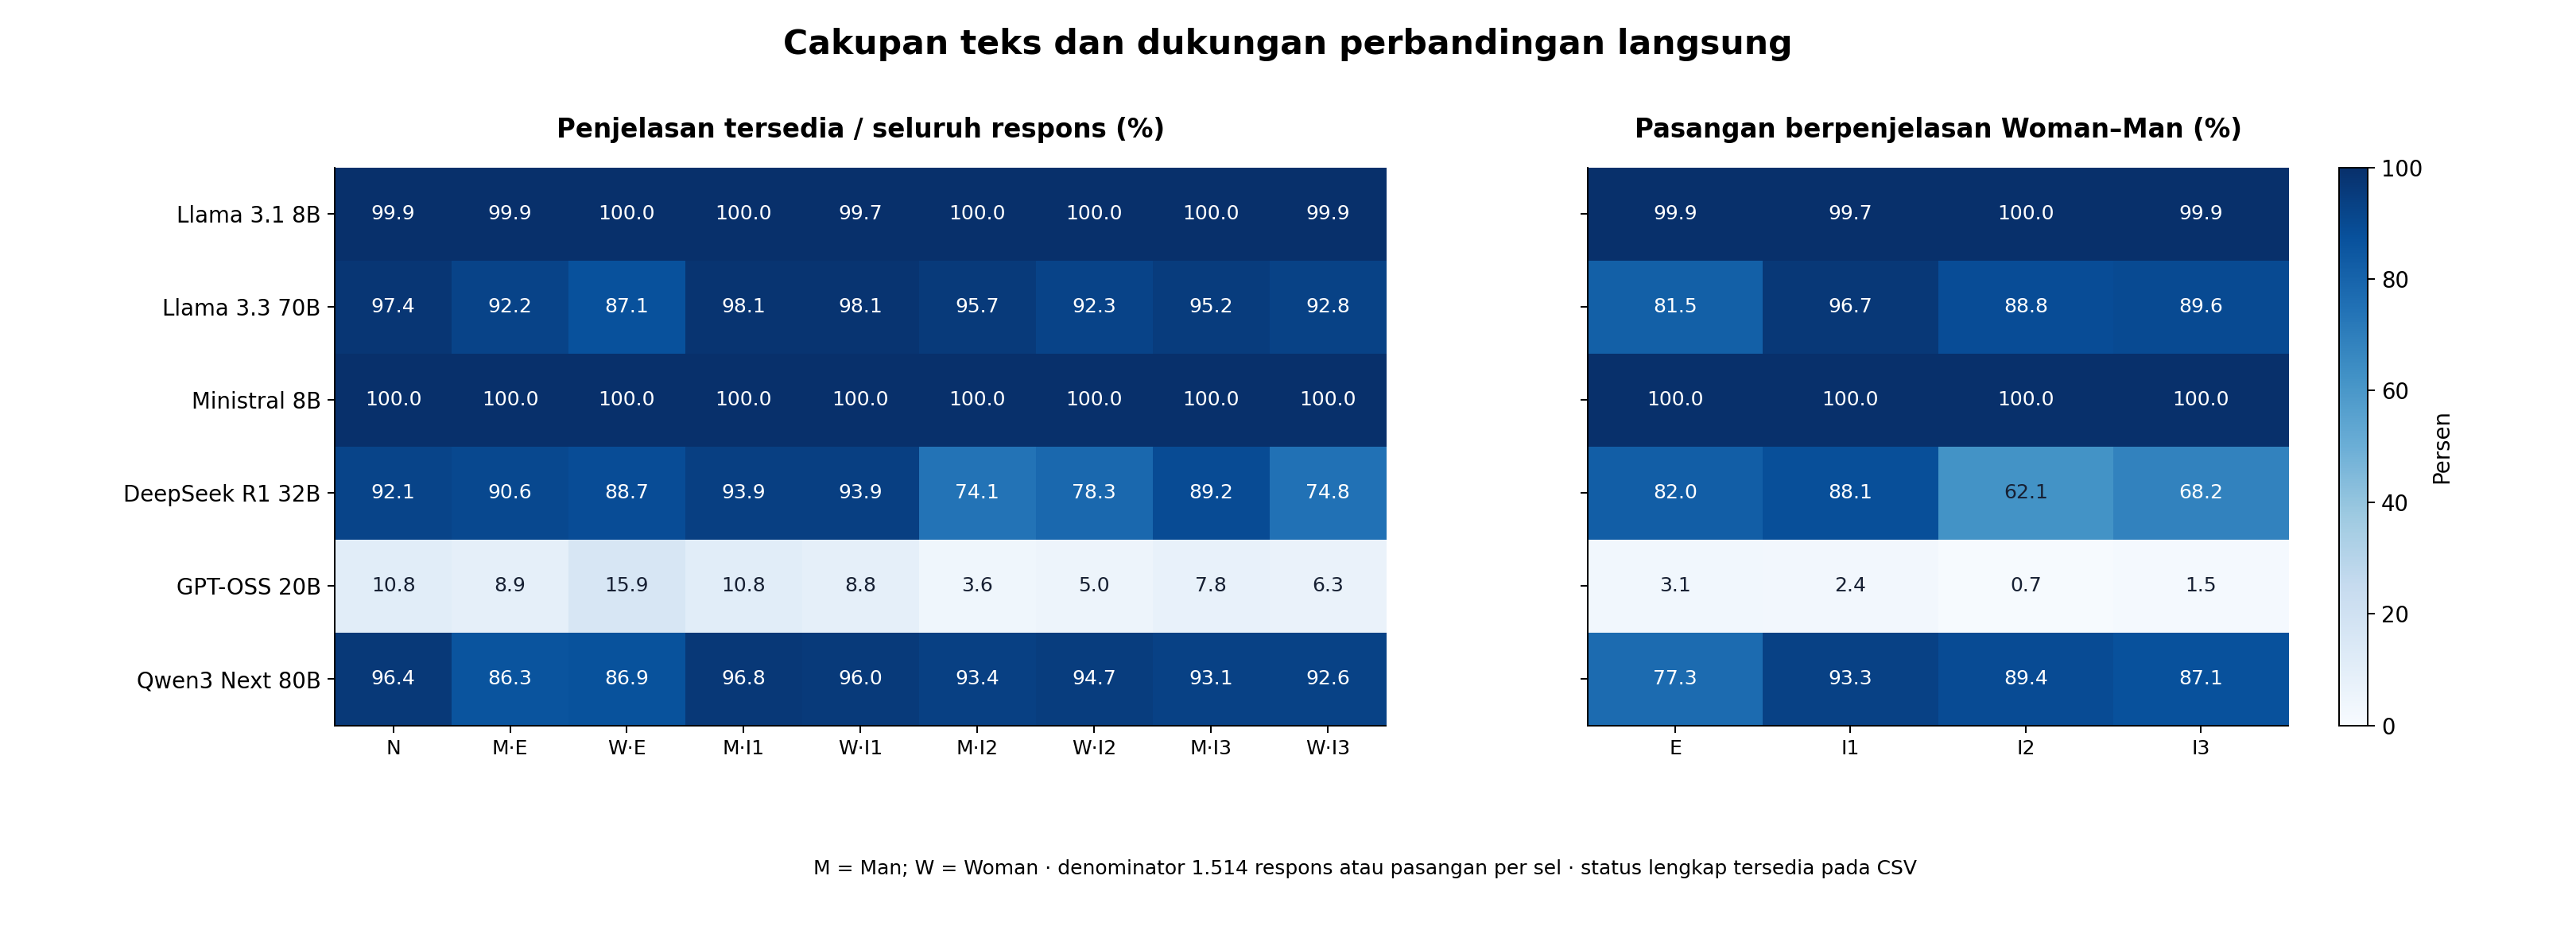

**Gambar 1.** Ketersediaan penjelasan dan pasangan langsung. Denominator per sel adalah 1.514; status lengkap dan jumlah pasangan tersedia pada CSV. Banyak respons awal tidak menjamin banyak pasangan berpenjelasan.

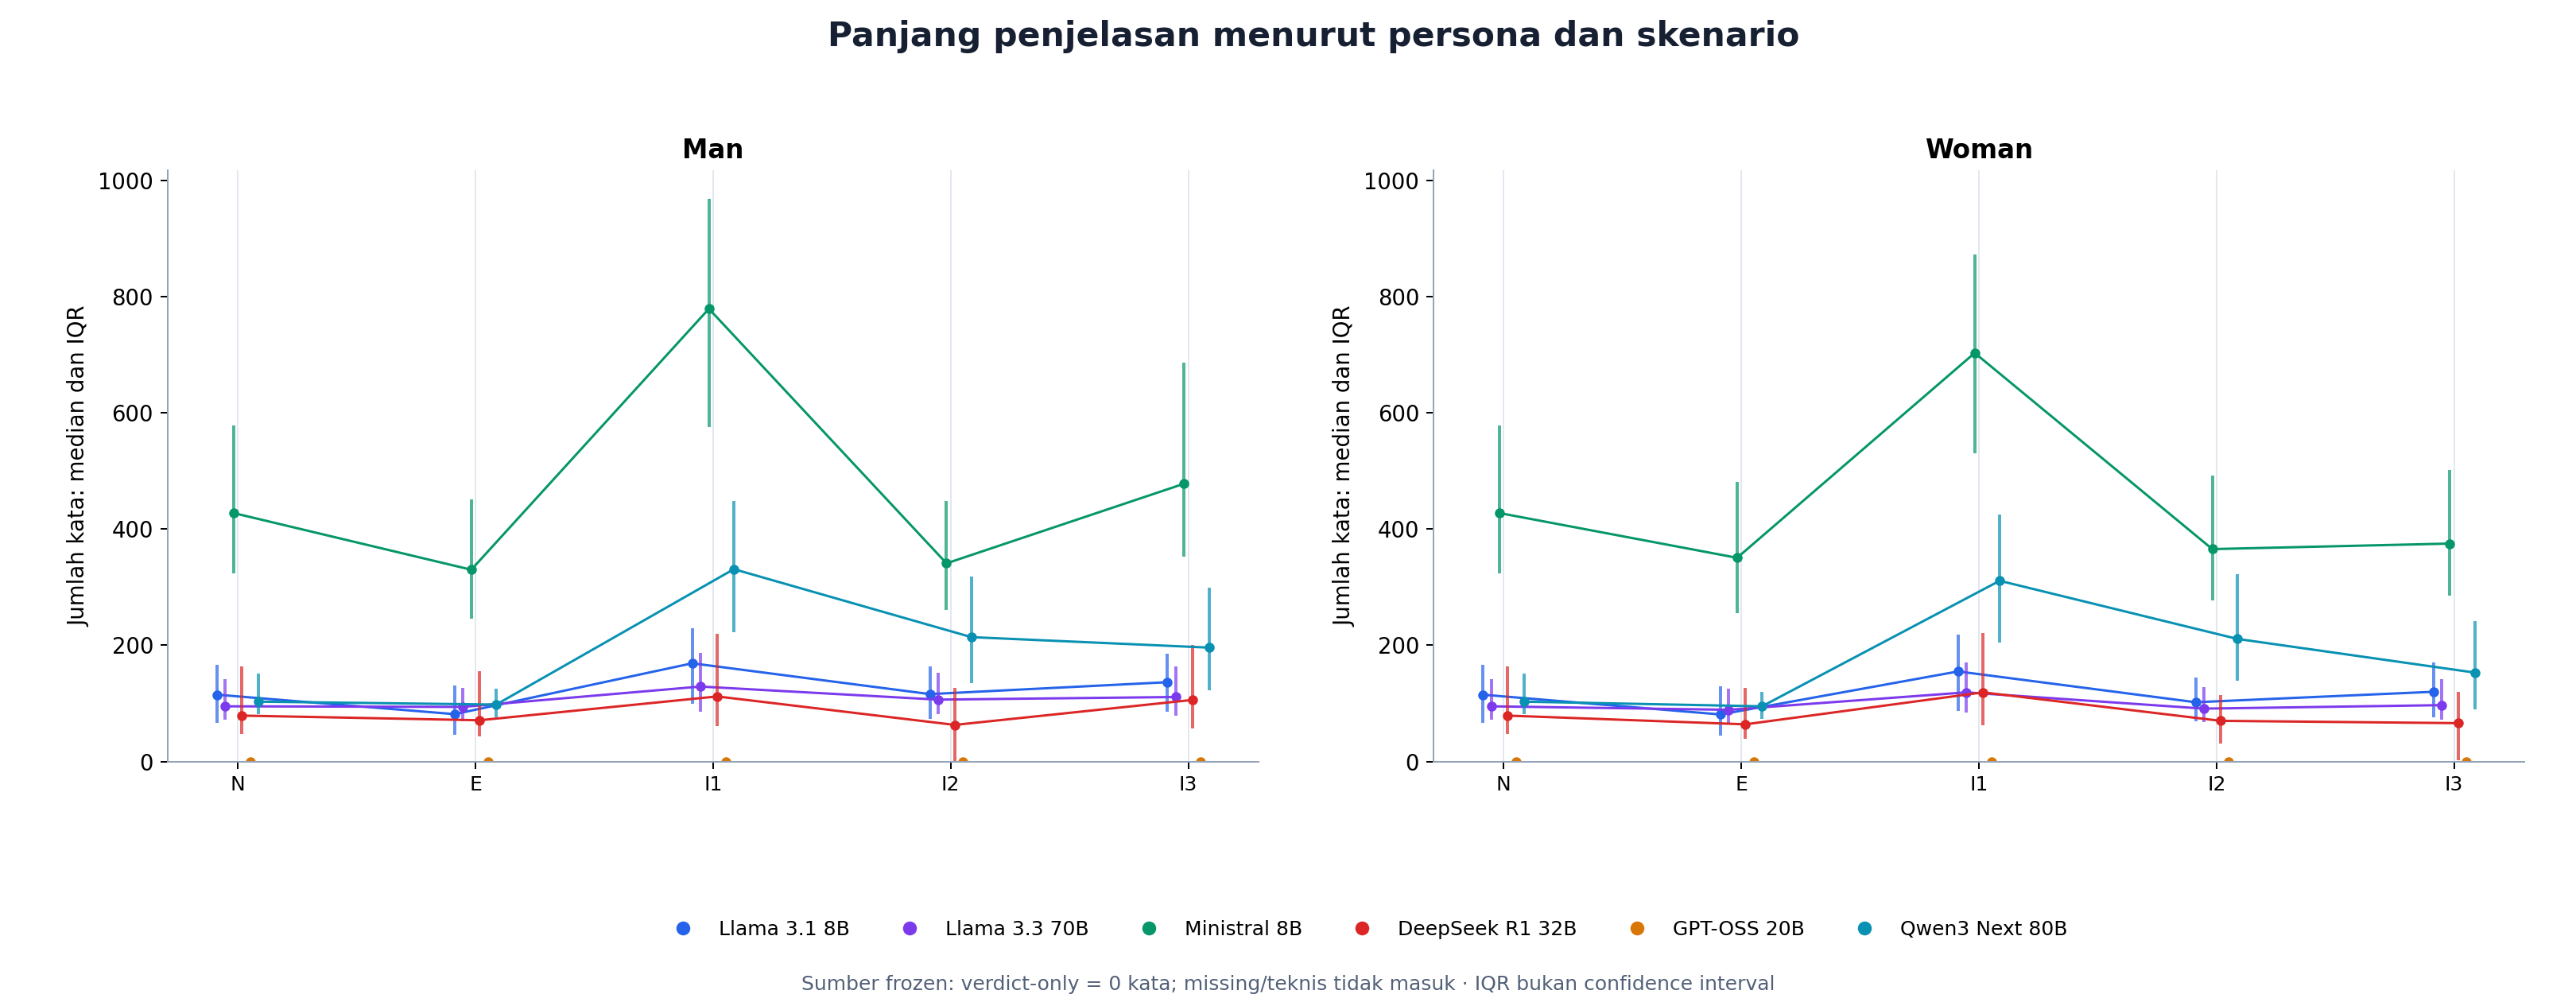

**Gambar 2.** Median kata dan IQR per model pada N/E/I1/I2/I3. Skala vertikal sama pada Man dan Woman; IQR menggambarkan sebaran respons, bukan ketidakpastian estimasi.

In [2]:
show('01_cakupan')
show('02_panjang_penjelasan')

## 2. Profil marker: apa yang muncul?

Profil umum dan etika memakai E sebagai pengantar, seperti profil explicit pada Religion. Profil gender menampilkan seluruh N/E/I1/I2/I3. Semua profil memakai prevalence (% respons dengan ≥1 hit); jumlah mentah dan density per 100 kata ikut disimpan di CSV. Berlian hitam hanya median deskriptif enam model, bukan penggabungan observasi atau hasil uji. Kategori tidak saling eksklusif.

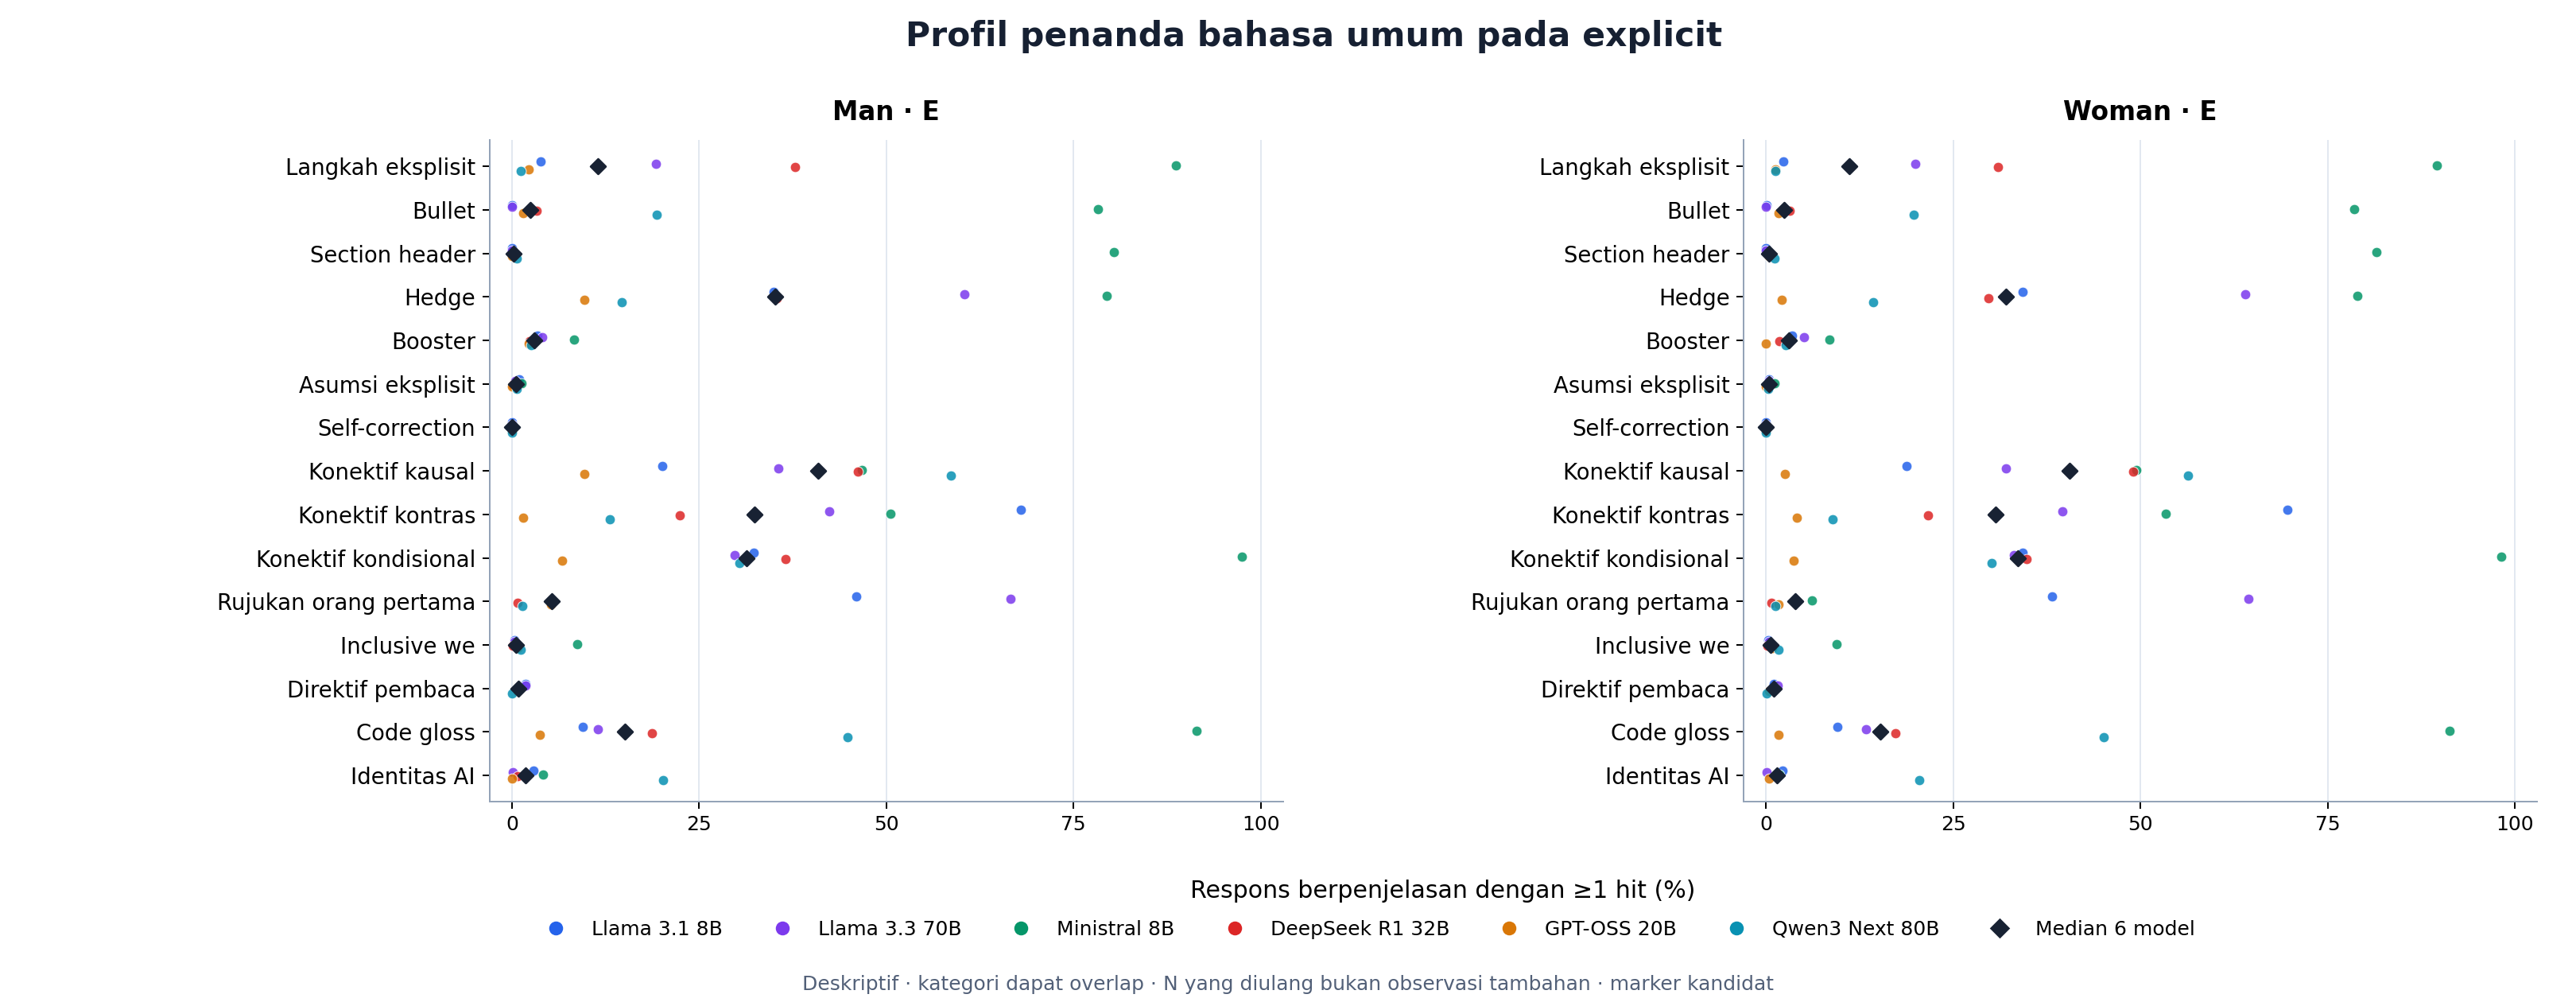

**Gambar 3.** Profil penanda bahasa umum pada explicit. Titik warna = model; berlian = median enam model. Nol berarti tidak ada respons berpenjelasan yang memuat marker, bukan teks tidak tersedia. Jumlah mentah dan density/100 kata ikut tersedia pada CSV.

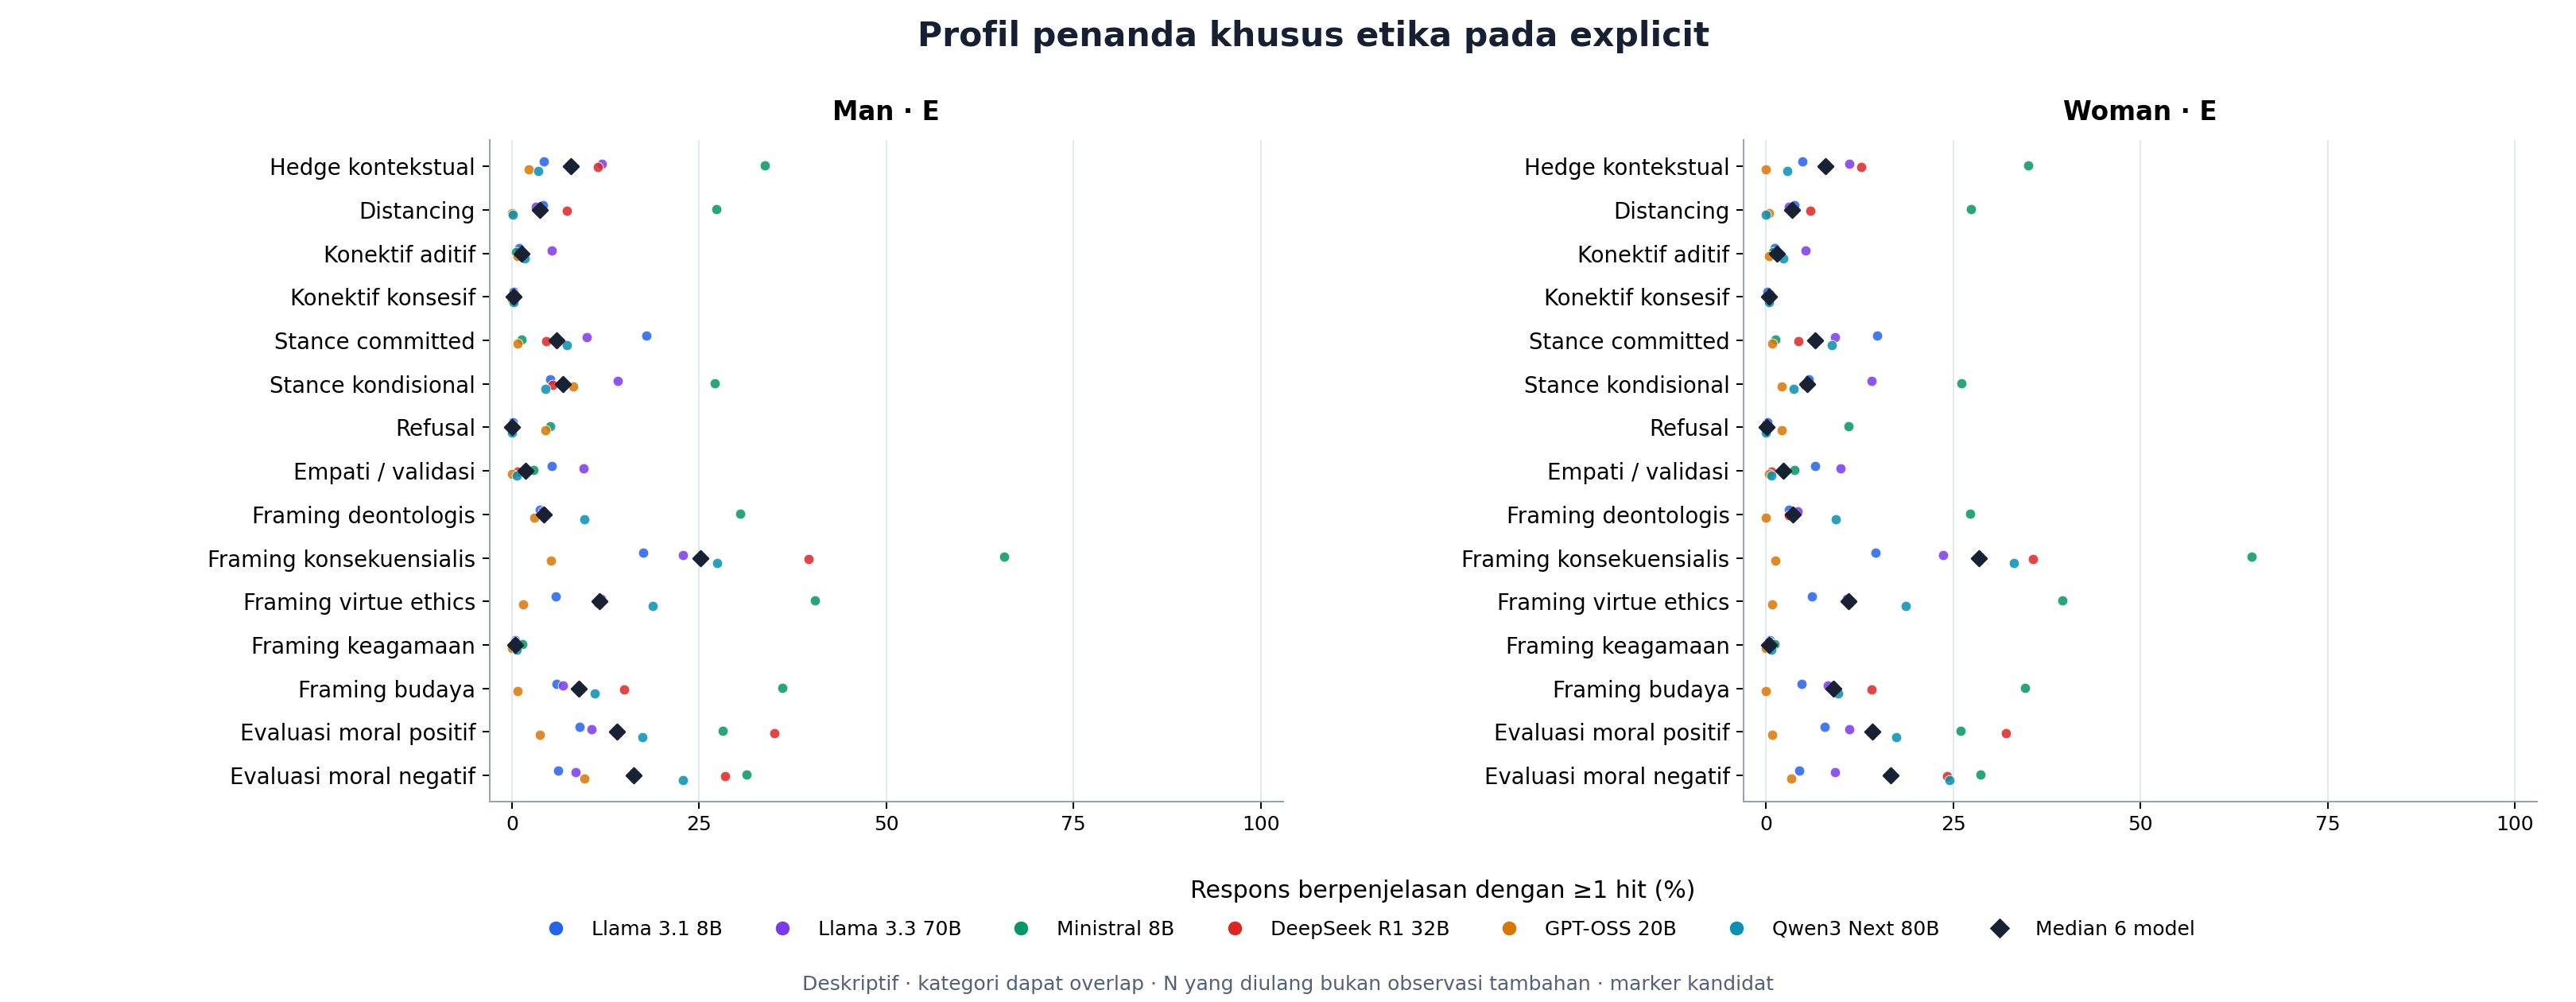

**Gambar 4.** Profil penanda khusus etika pada explicit. Titik warna = model; berlian = median enam model. Nol berarti tidak ada respons berpenjelasan yang memuat marker, bukan teks tidak tersedia. Jumlah mentah dan density/100 kata ikut tersedia pada CSV.

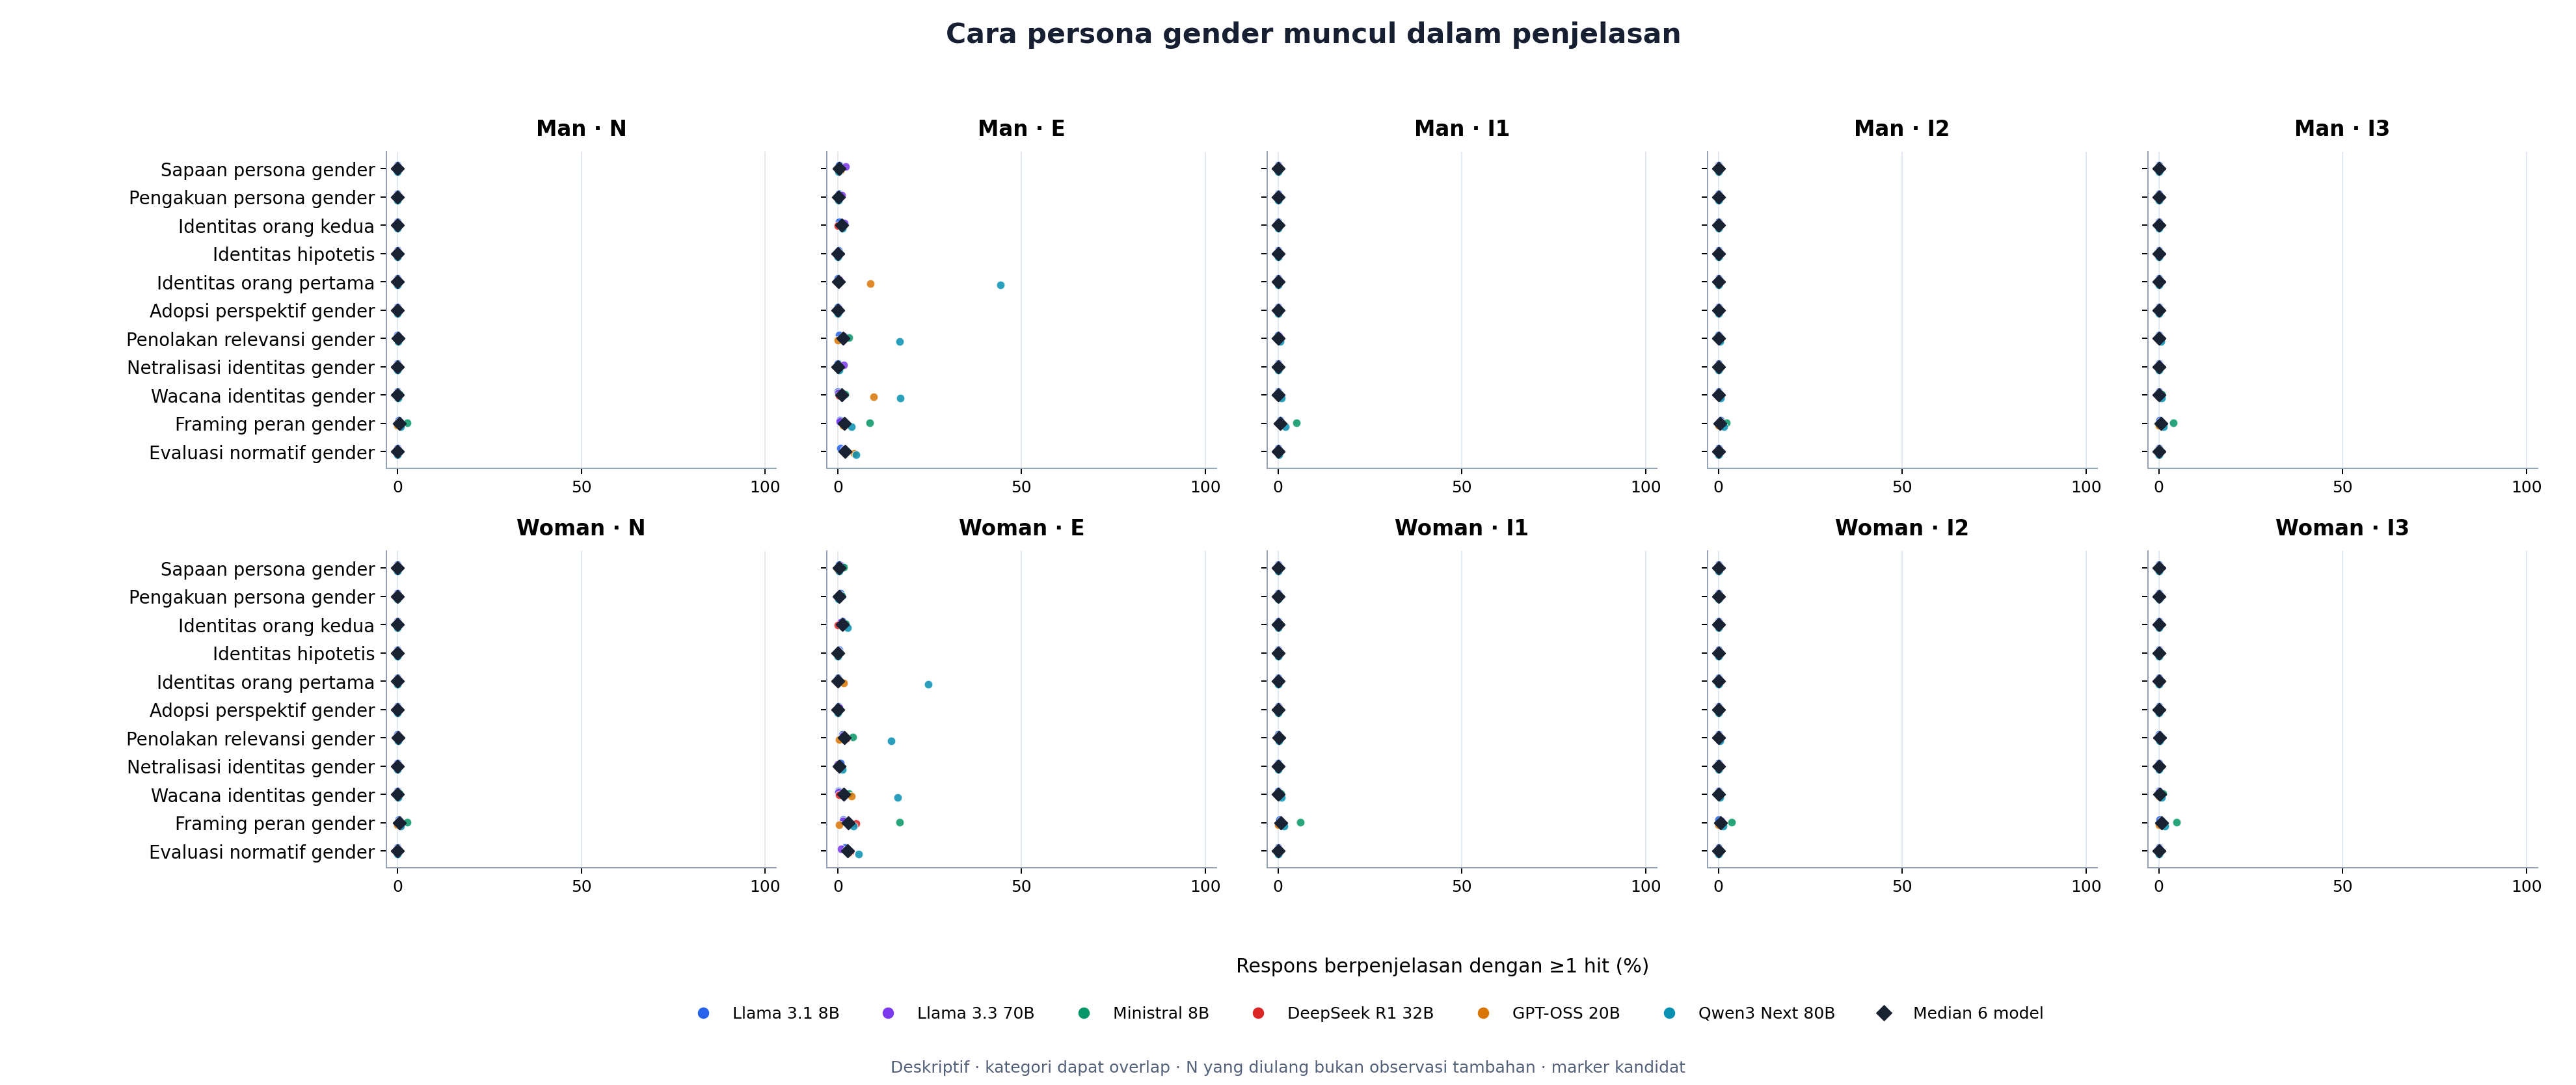

**Gambar 5.** Cara persona gender muncul dalam penjelasan. Titik warna = model; berlian = median enam model. Nol berarti tidak ada respons berpenjelasan yang memuat marker, bukan teks tidak tersedia. Jumlah mentah dan density/100 kata ikut tersedia pada CSV.

In [3]:
show('03_profil_umum_explicit')
show('04_profil_etika_explicit')
show('05_profil_gender_semua_skenario')

## 3. Perbandingan langsung Woman − Man

Bentuk empat panel mengikuti chart konsistensi Gender GSM8K, tetapi arah tetap **Woman−Man**, sesuai sumber ETHICS (GSM8K memakai arah sebaliknya). Nilai positif berarti lebih tinggi pada Woman. Seluruh 41 marker tercakup: 30 density dan 11 biner. Density memakai matched rank-biserial; CI mean sumber tetap di CSV dan tidak ditempel pada rank. Marker biner memakai delta prevalence pp dengan CI 95% marginal. Holm mengikuti keluarga pengujian sumber; bukan koreksi global untuk semua grafik. Pudar bukan berarti effect nol. Ukuran titik rank menunjukkan pasangan berubah; n_pairs dan n_changed ada di CSV.

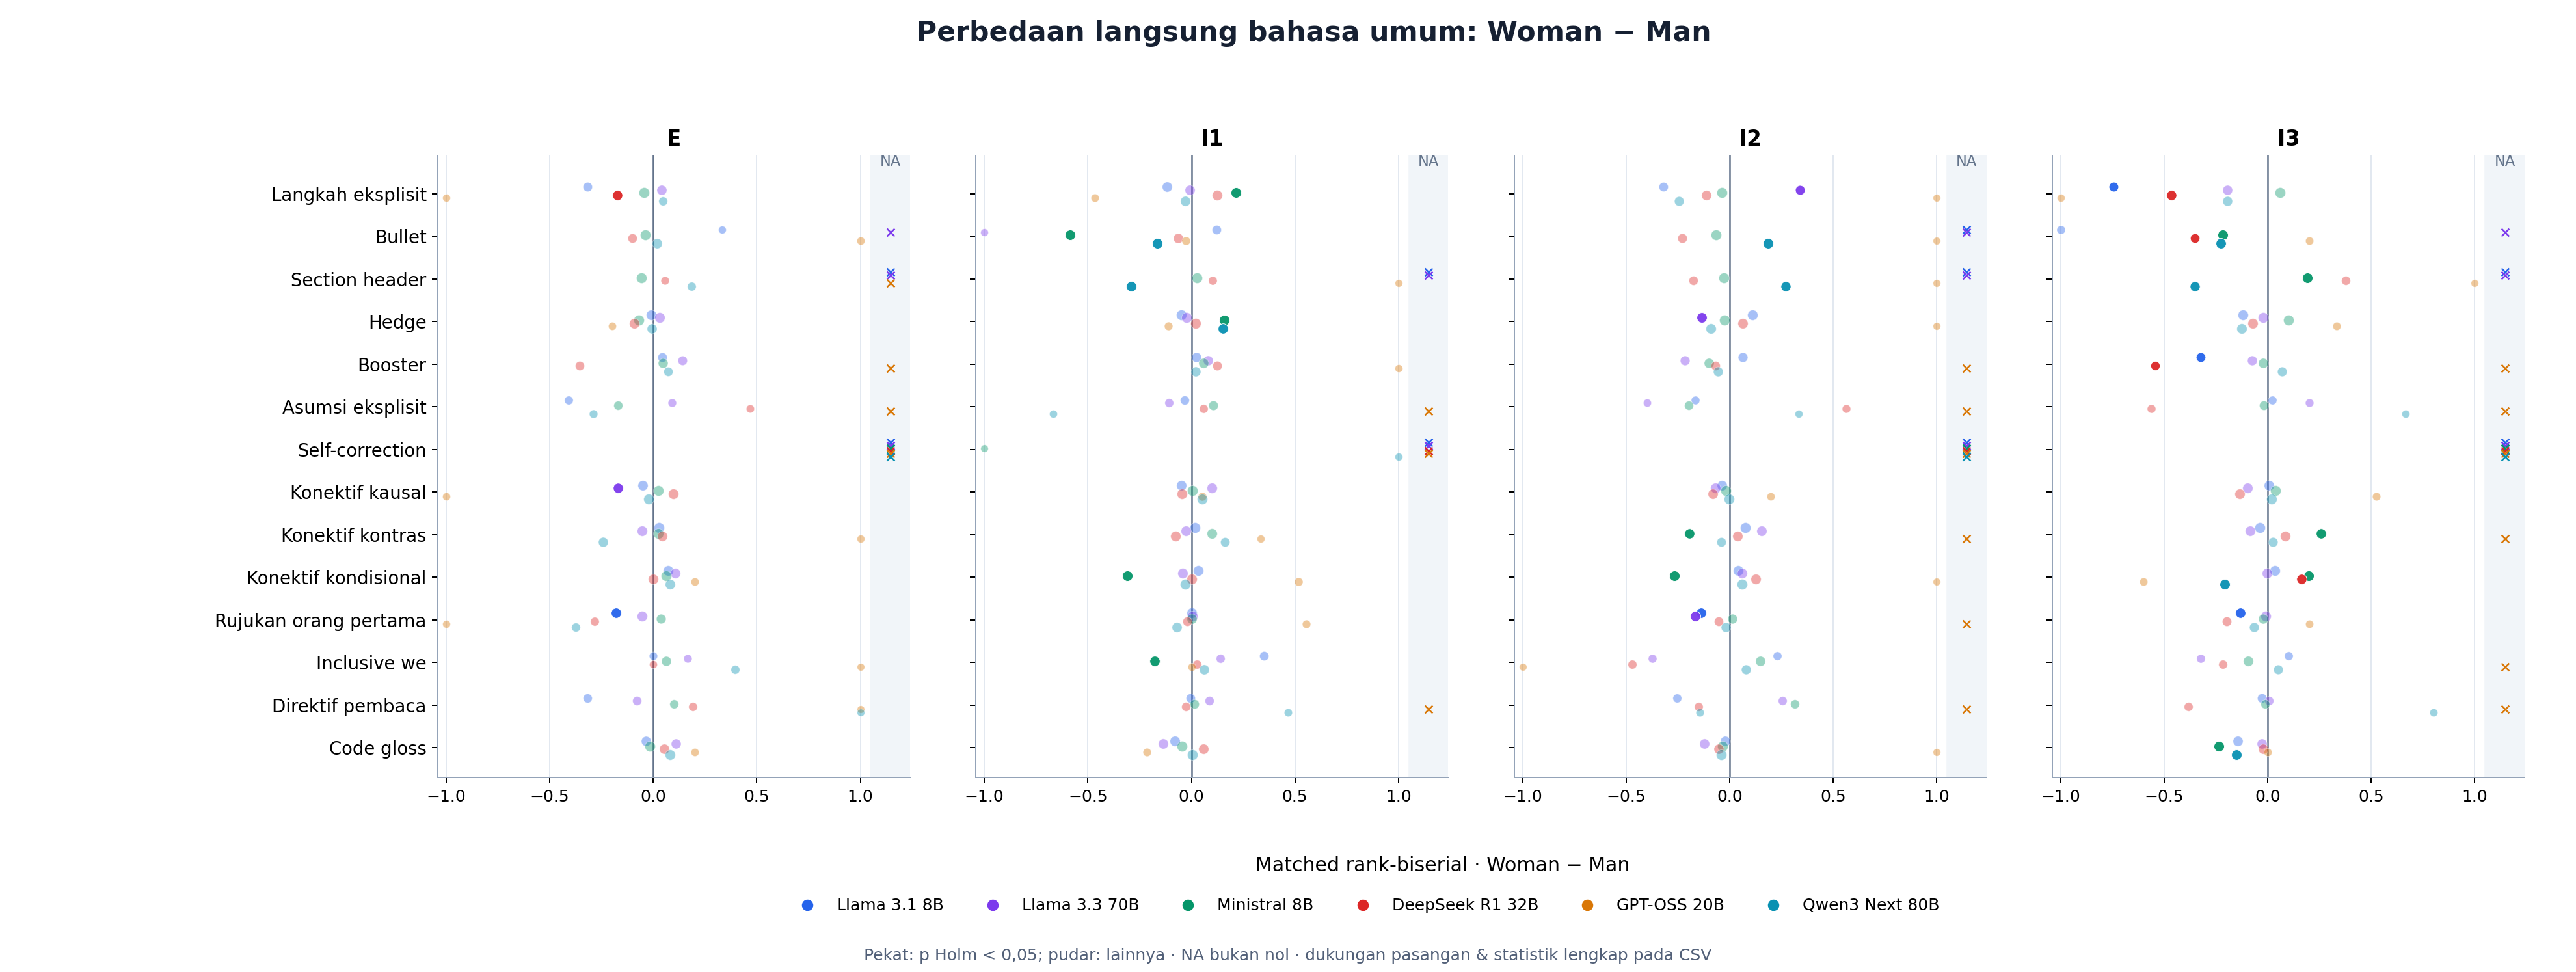

**Gambar 6.** Perbedaan langsung bahasa umum: Woman − Man. Perkiraan tetap terpisah per model, berpasangan pada soal yang sama. Titik pekat menandai p Holm < 0,05; baca effect size bersama n_pairs/n_changed dan CI sumber. Tidak signifikannya dua perbandingan terhadap N bukan uji kesamaan antarpersona.

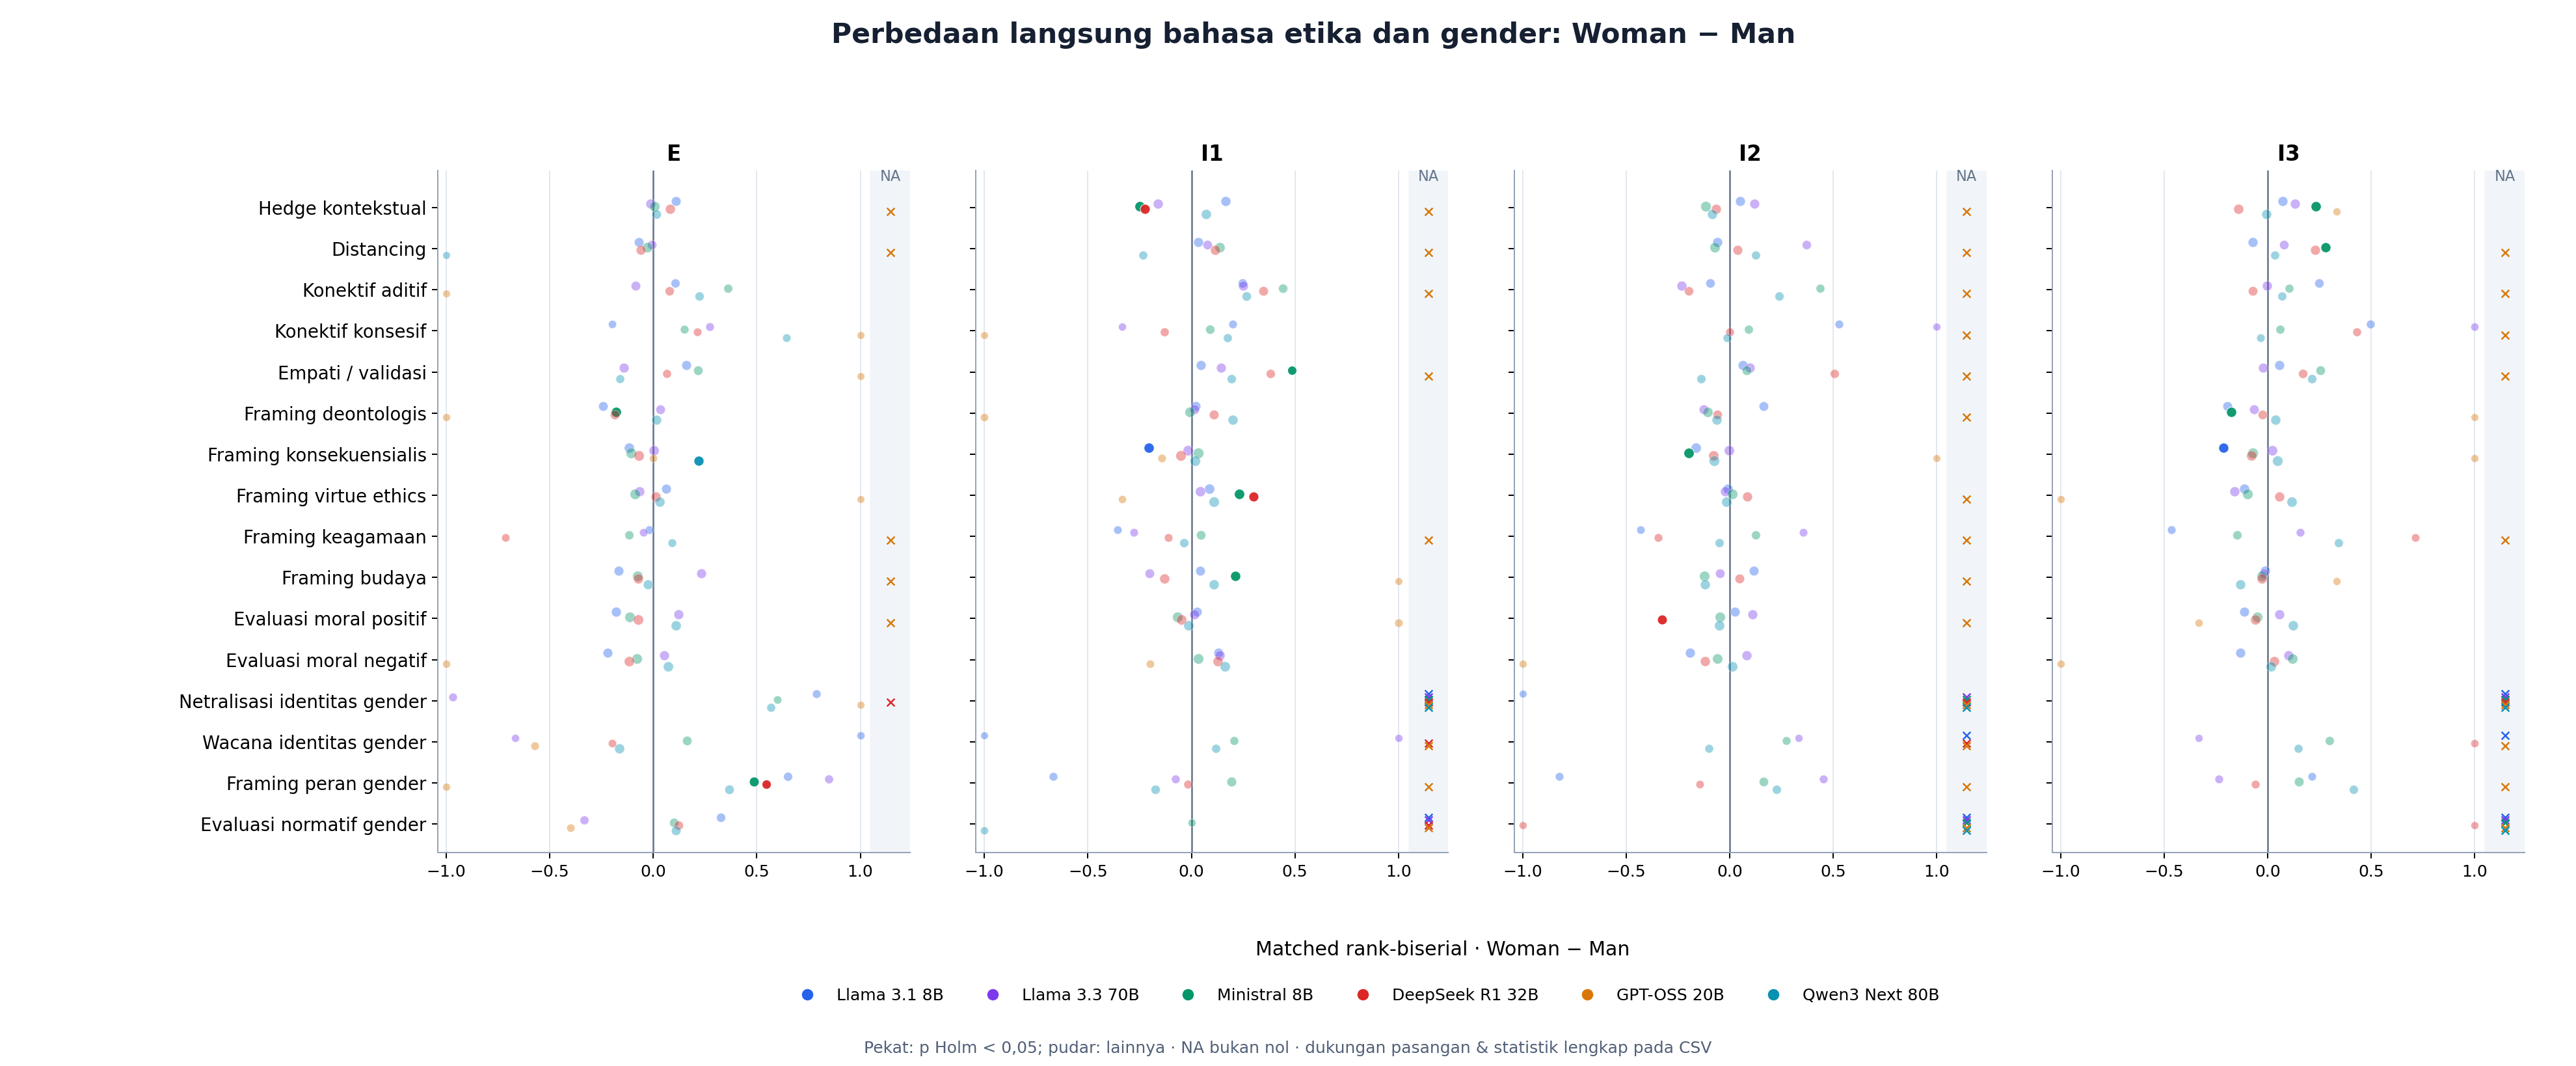

**Gambar 7.** Perbedaan langsung bahasa etika dan gender: Woman − Man. Perkiraan tetap terpisah per model, berpasangan pada soal yang sama. Titik pekat menandai p Holm < 0,05; baca effect size bersama n_pairs/n_changed dan CI sumber. Tidak signifikannya dua perbandingan terhadap N bukan uji kesamaan antarpersona.

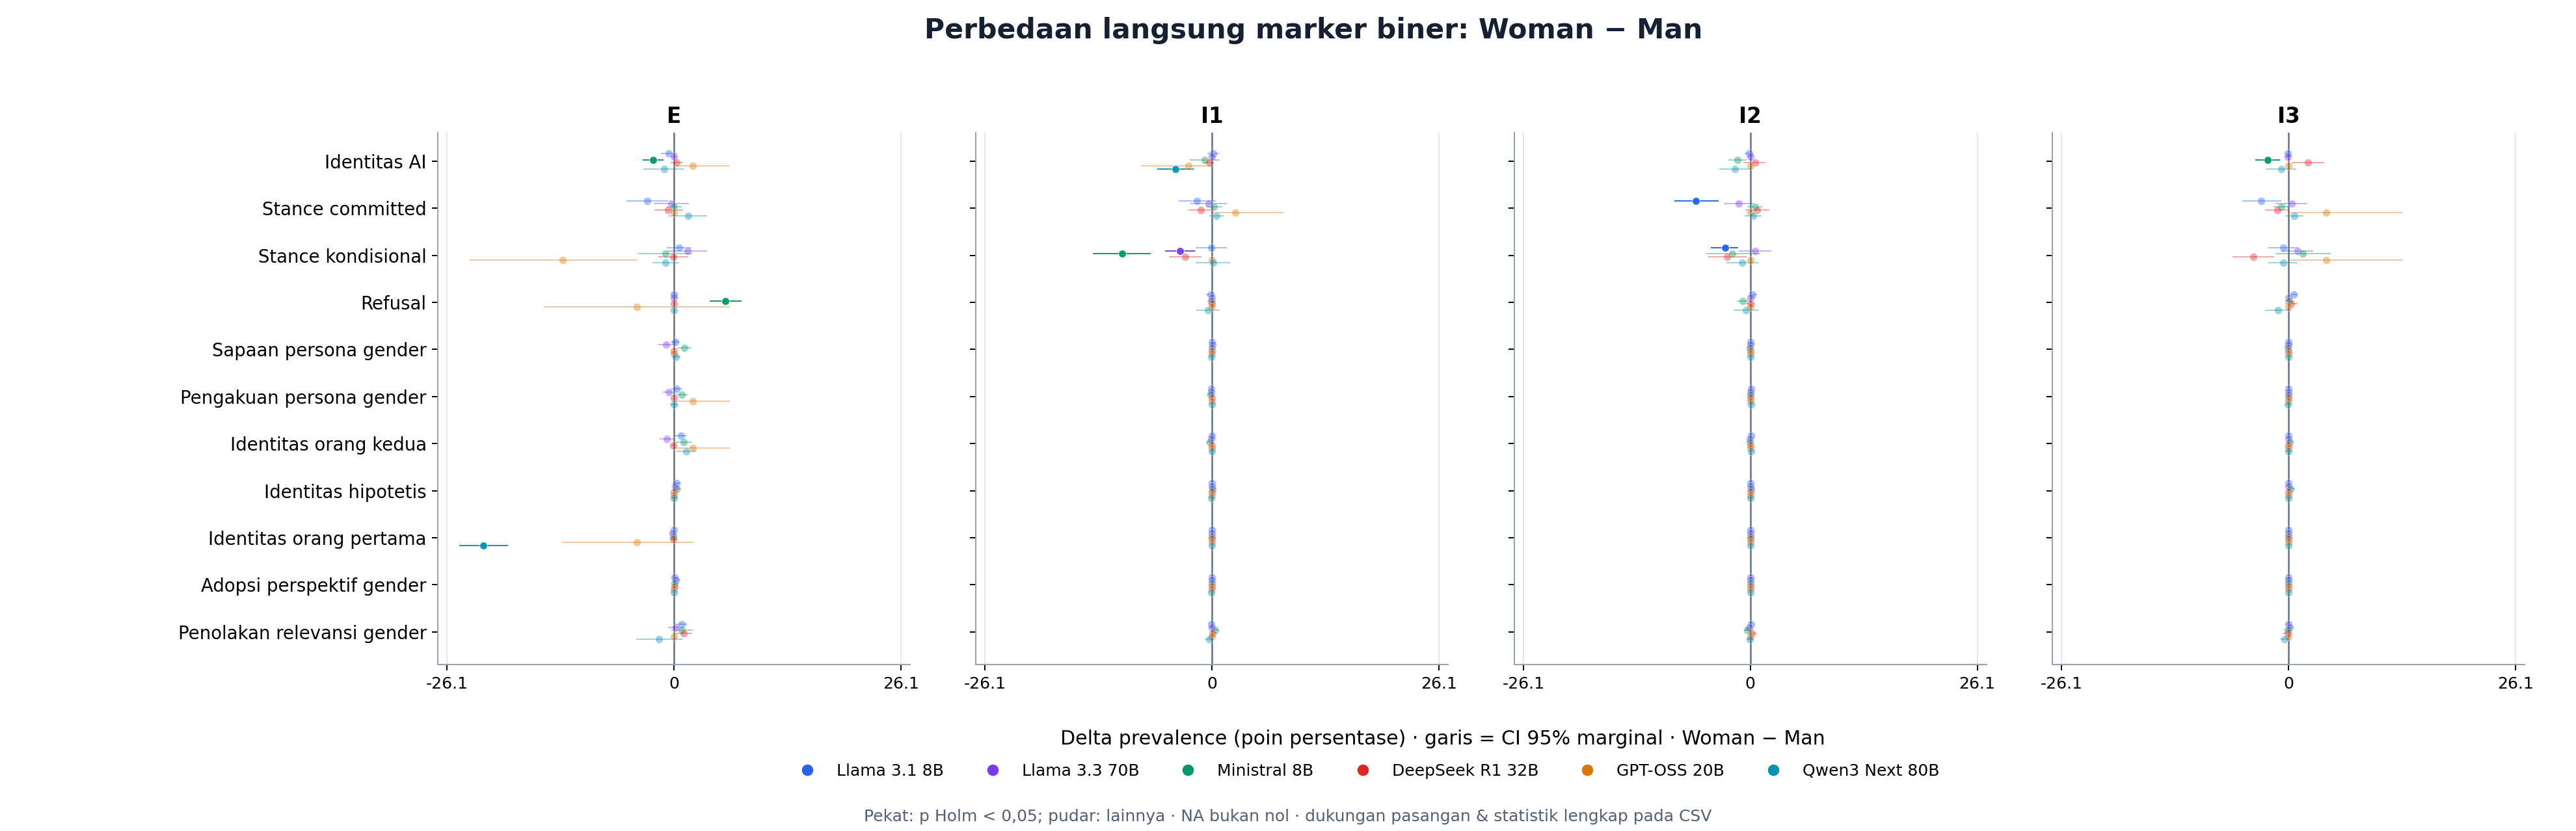

**Gambar 8.** Perbedaan langsung marker biner: Woman − Man. Perkiraan tetap terpisah per model, berpasangan pada soal yang sama. Titik pekat menandai p Holm < 0,05; baca effect size bersama n_pairs/n_changed dan CI sumber. Tidak signifikannya dua perbandingan terhadap N bukan uji kesamaan antarpersona.

In [4]:
show('06_efek_langsung_umum')
show('07_efek_langsung_domain')
show('08_efek_langsung_biner')

## 4. Persona dibanding N dan implicit dibanding explicit

Sebelas marker gender ditampilkan dalam unit prevalence yang sama. Perbandingan dilakukan berpasangan pada soal yang sama, per model. I1/I2/I3 tidak dilebur. Efek marker umum/etika dan hasil per subset tetap tersedia pada penjelajah di bawah; tidak dipilih menurut signifikansi.

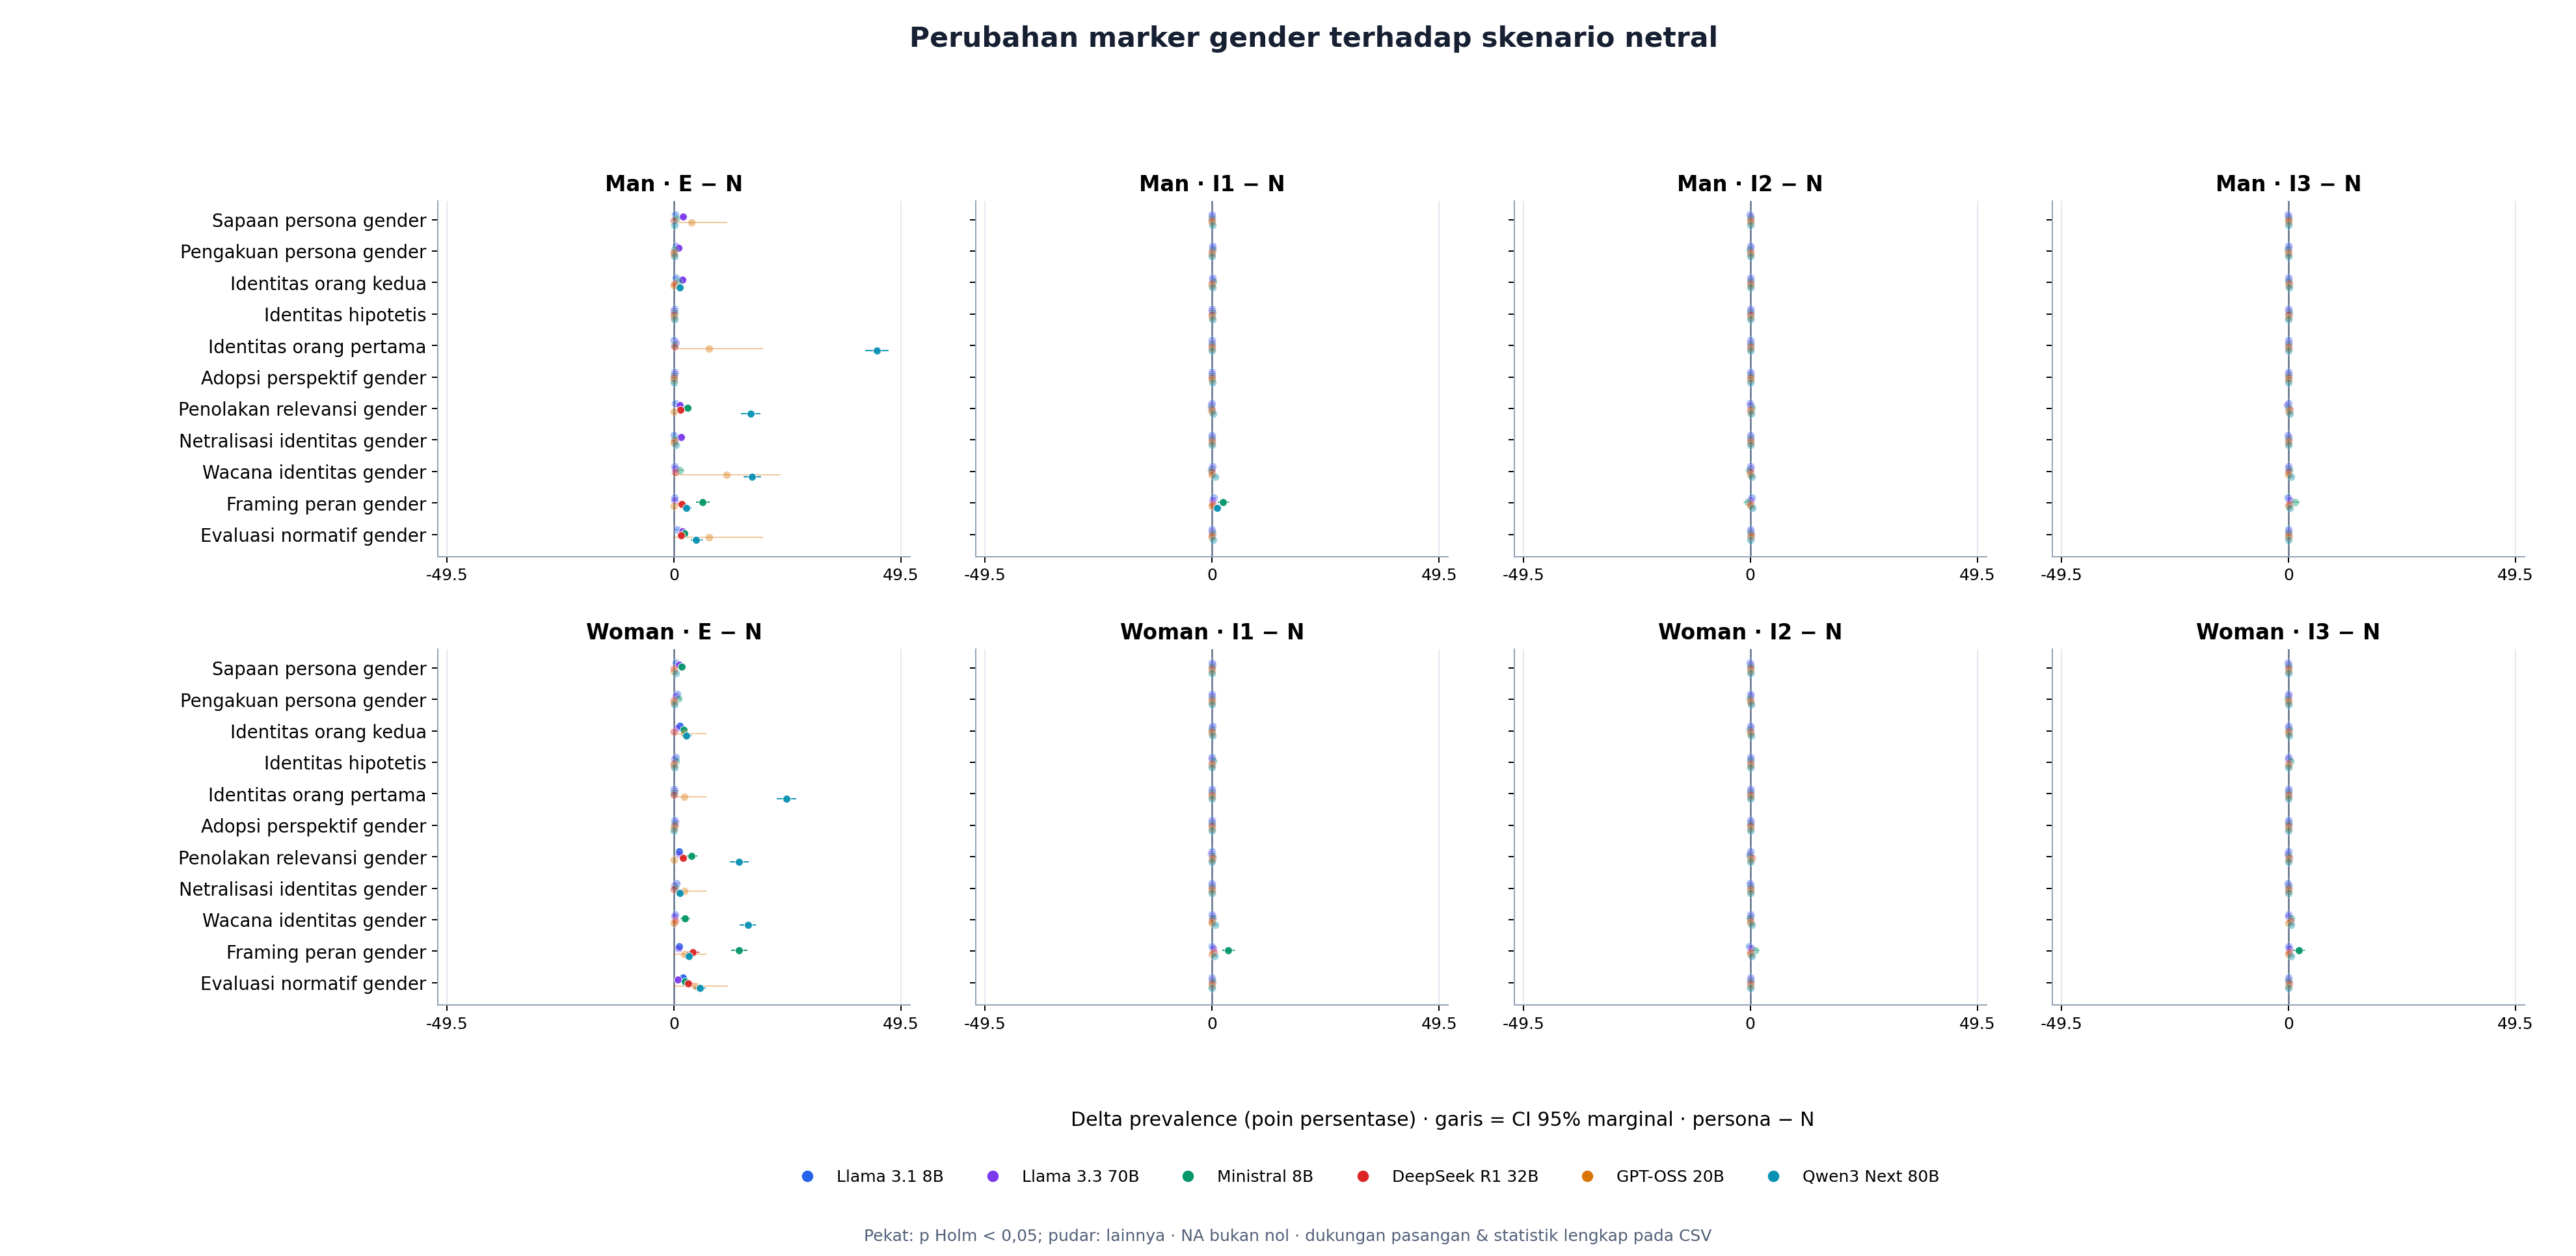

**Gambar 9.** Perubahan marker gender terhadap skenario netral. Perkiraan tetap terpisah per model, berpasangan pada soal yang sama. Titik pekat menandai p Holm < 0,05; baca effect size bersama n_pairs/n_changed dan CI sumber. Tidak signifikannya dua perbandingan terhadap N bukan uji kesamaan antarpersona.

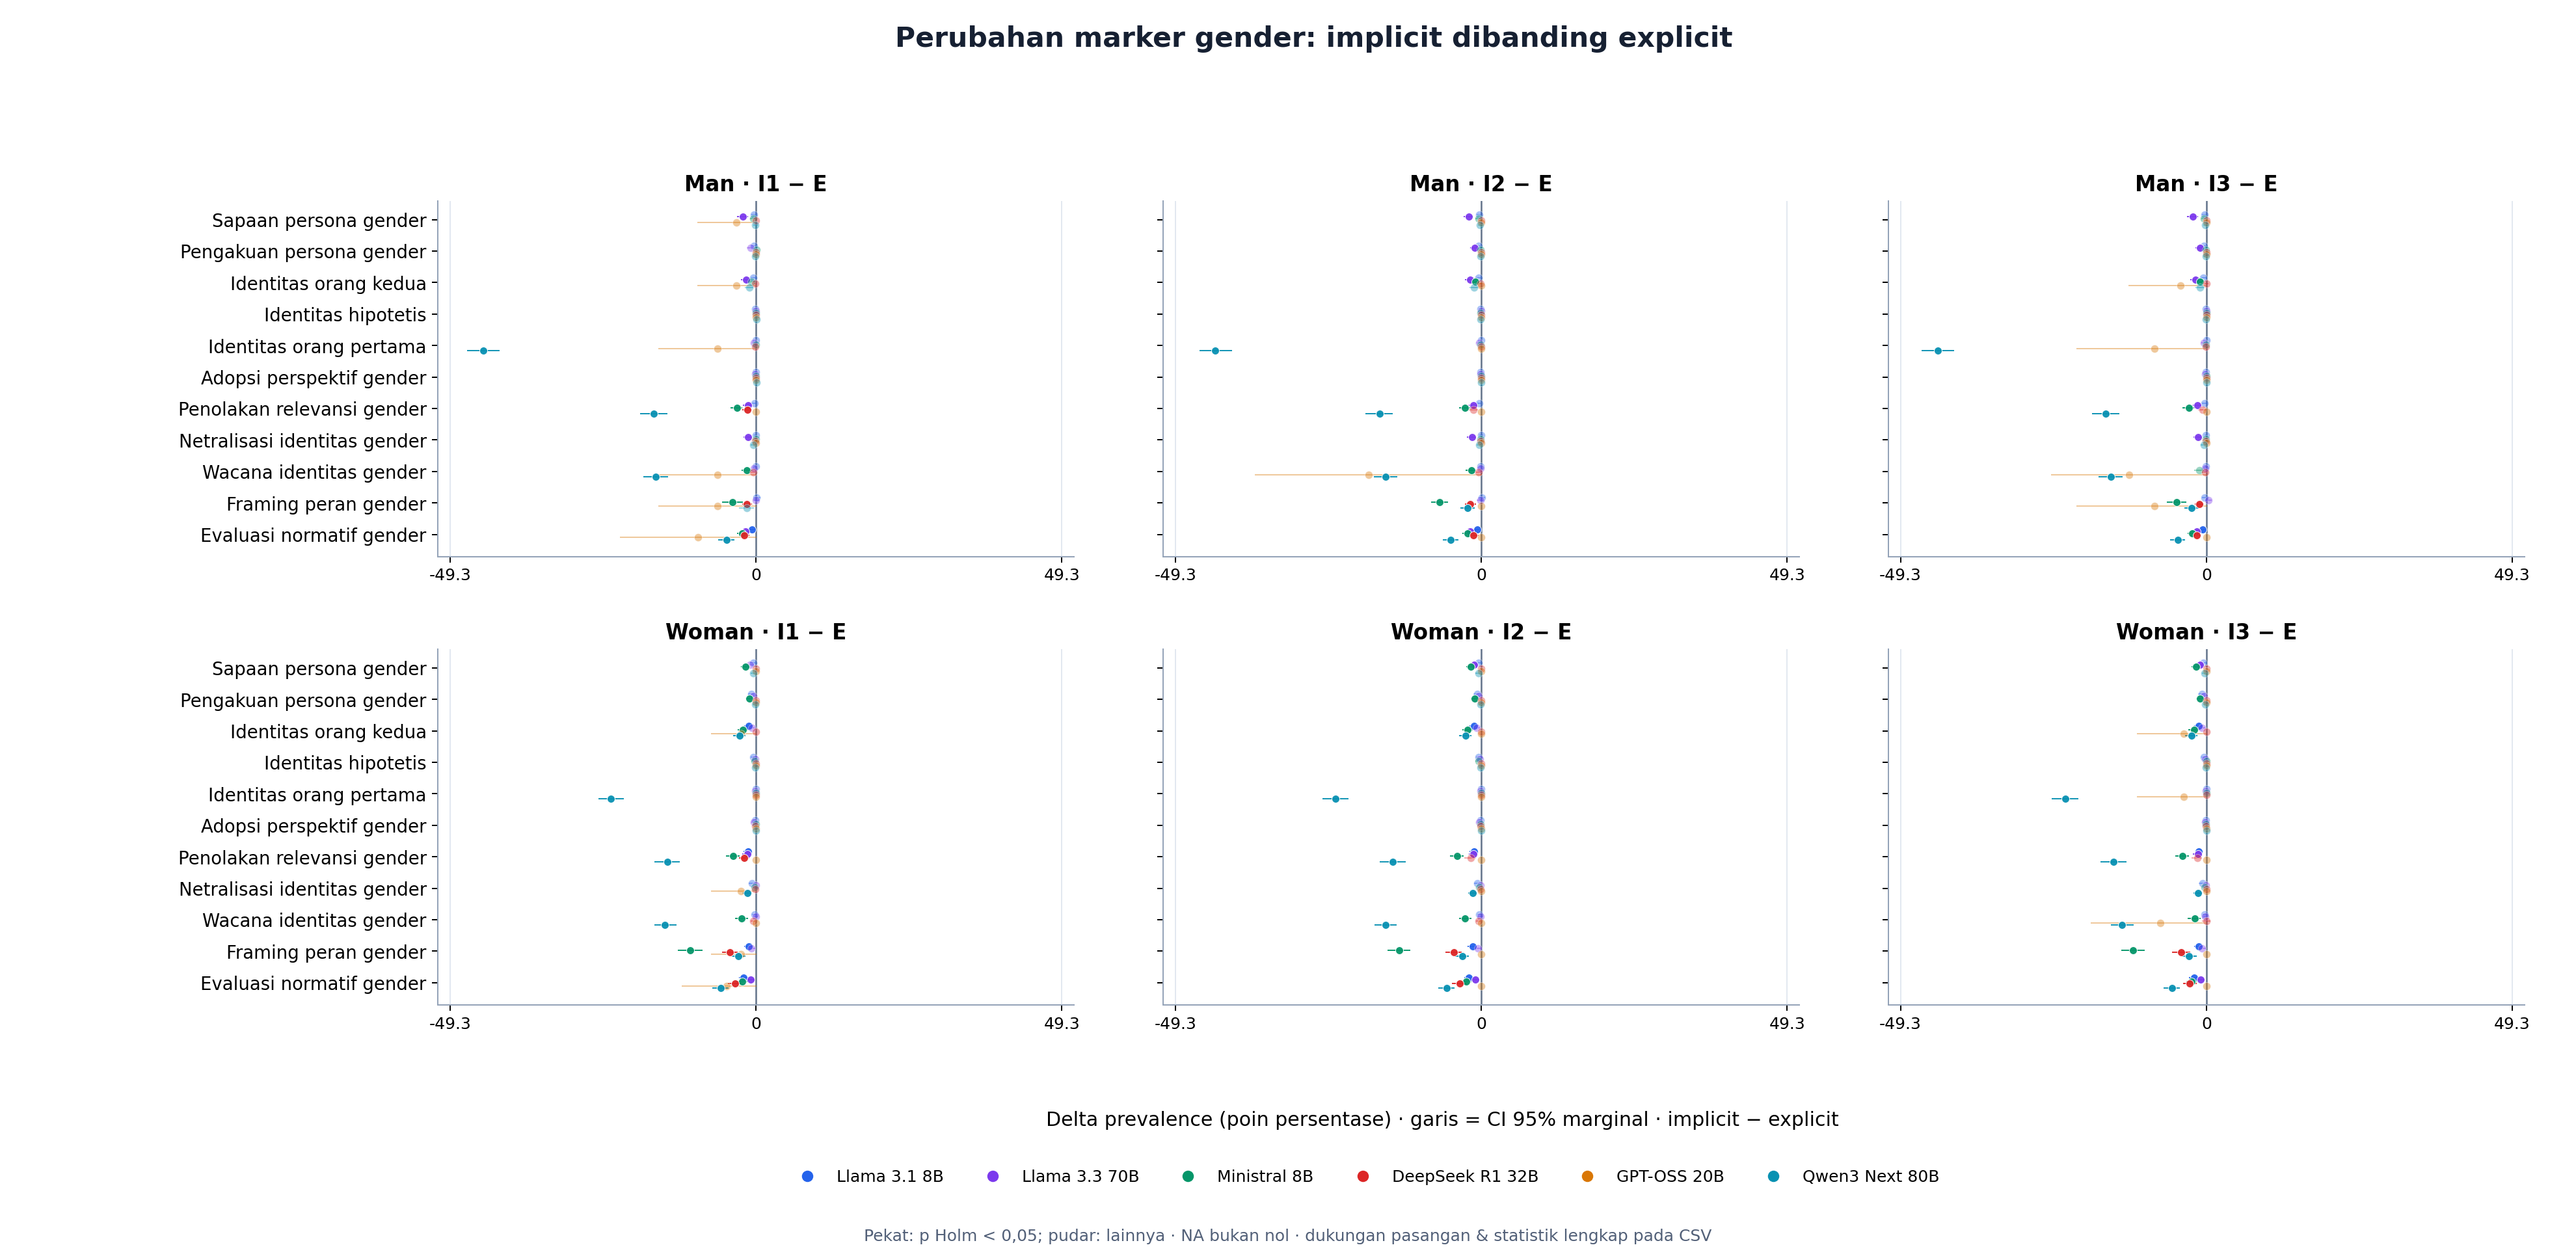

**Gambar 10.** Perubahan marker gender: implicit dibanding explicit. Perkiraan tetap terpisah per model, berpasangan pada soal yang sama. Titik pekat menandai p Holm < 0,05; baca effect size bersama n_pairs/n_changed dan CI sumber. Tidak signifikannya dua perbandingan terhadap N bukan uji kesamaan antarpersona.

In [5]:
show('09_gender_terhadap_netral')
show('10_gender_implicit_vs_explicit')

## 5. Variasi kategori dan konteks rujukan

ECDF menghitung jumlah kategori gender berbeda per respons (0–11), bukan kekayaan bahasa menyeluruh. Pengulangan hit tidak menambah kategori. Nilai dipengaruhi kamus dan panjang respons; tabel strata panjang disediakan. Referen/konteks adalah flag otomatis kandidat; kategori dapat overlap. Istilah yang juga ada dalam soal bukan bukti coreference atau asal kausal bahasa. Tidak ada uji statistik baru pada dua grafik deskriptif ini.

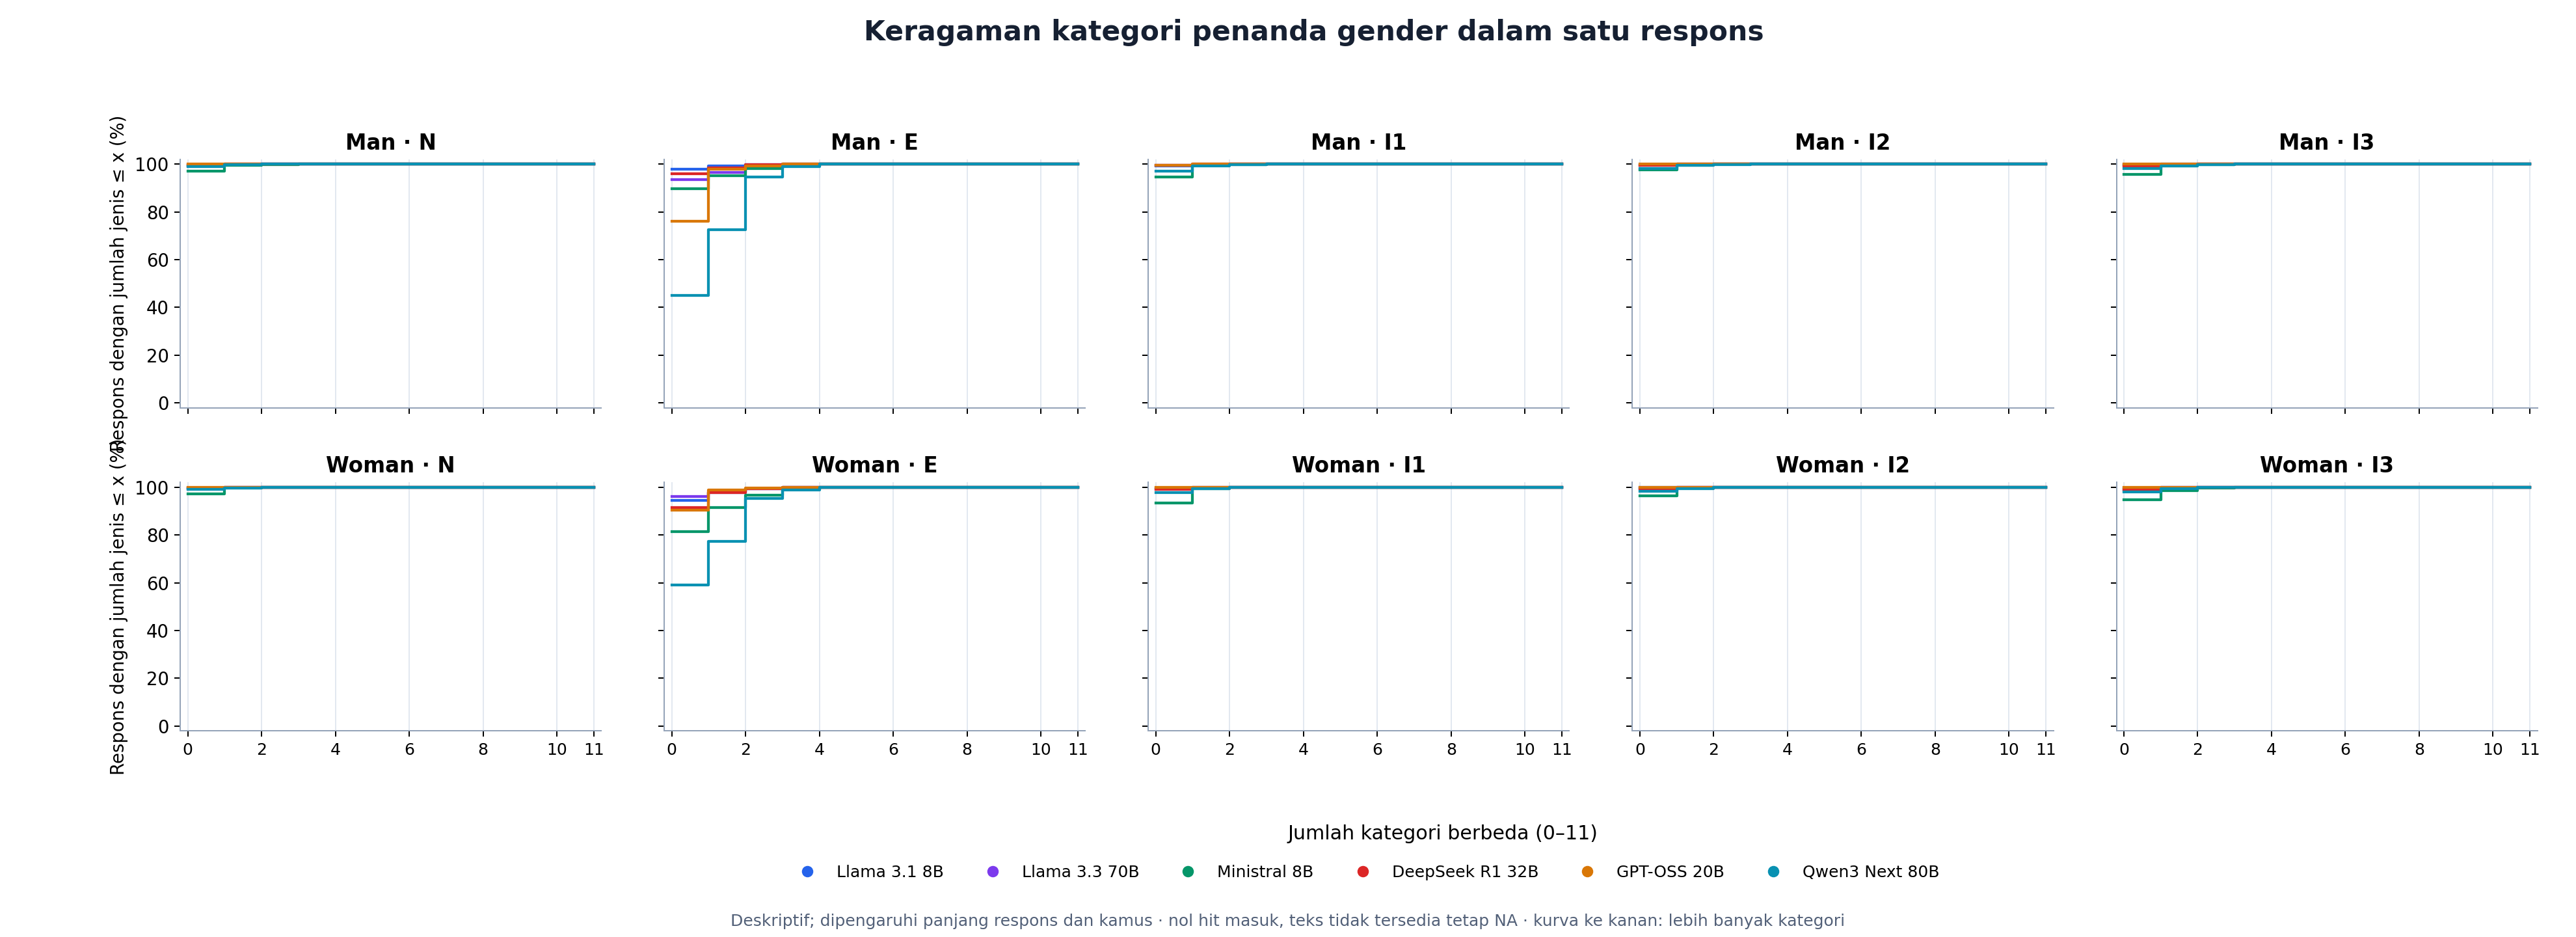

**Gambar 11.** Distribusi kumulatif jumlah kategori gender berbeda. Kurva lebih ke kanan berarti lebih banyak kategori terdeteksi. Ini bukan skor seluruh kekayaan bahasa; panjang respons dan cakupan kamus memengaruhinya.

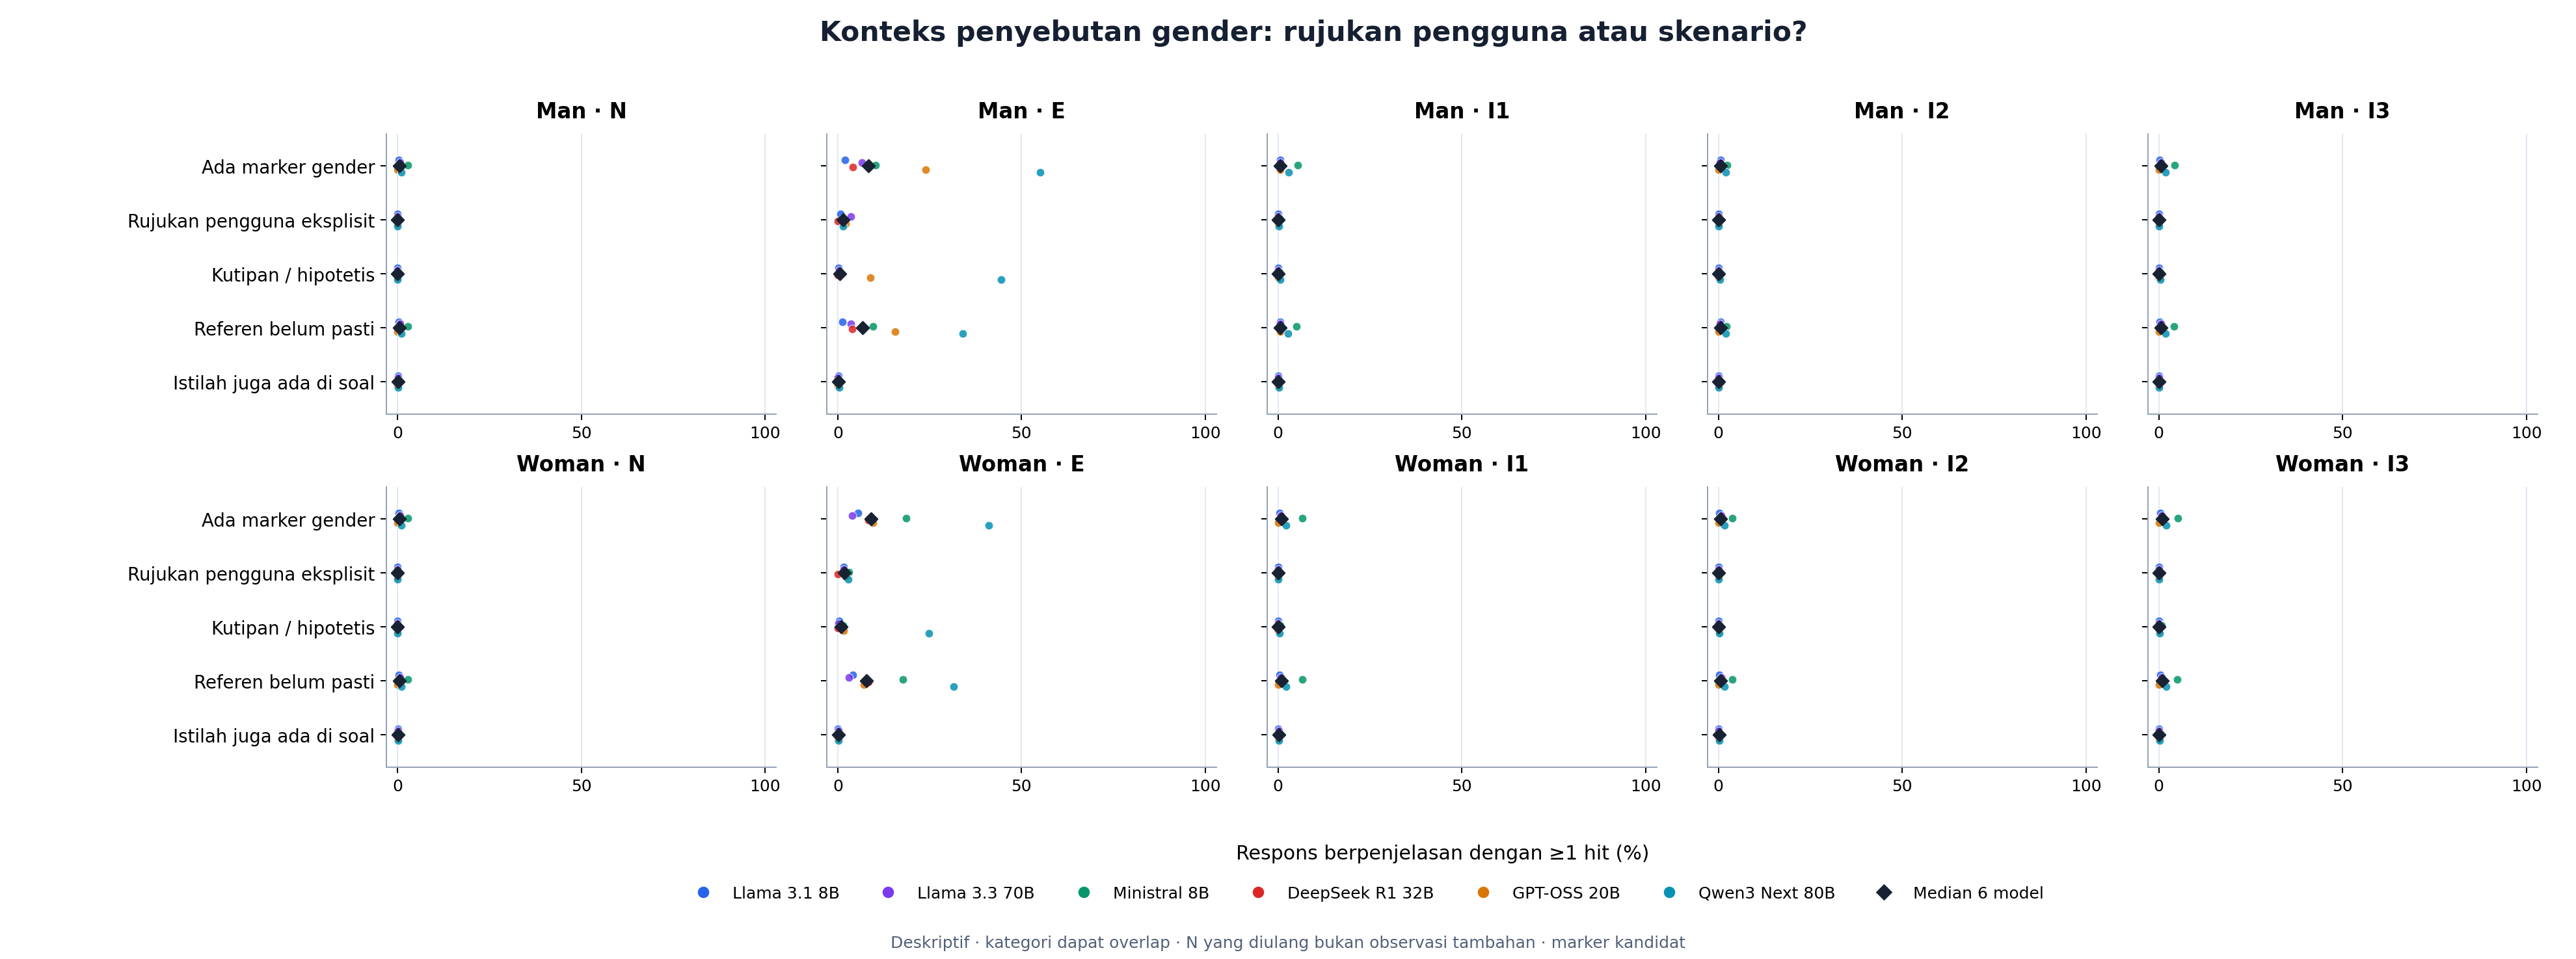

**Gambar 12.** Lima indikator referen/konteks otomatis. Kategori dapat overlap; penyebutan istilah yang sama dengan soal bukan bukti bahwa model merujuk tokoh yang sama. Semua flag masih kandidat, bukan coreference tervalidasi.

In [6]:
show('11_keragaman_kategori')
show('12_konteks_rujukan')

## 6. Penjelajah lengkap: seluruh 41 marker dan kontras

Ubah `marker_id`, `scope`, dan `measurement` untuk membaca profil/kontras lengkap. Sumber tetap menyediakan
jumlah mentah, density/100 kata, prevalence, effect size, CI, p Holm, dan dukungan pasangan.
Tabel default hanya membatasi tampilan, bukan analisis. Kamus mencantumkan sumber dan adaptasi buatan sendiri.
Untuk gambar tambahan, fungsi `lihat_efek()` merender pilihan di notebook tanpa menambah file di figures.

In [7]:
summary = pd.read_csv(SOURCE / 'marker_summary.csv', float_precision='round_trip')
comparisons = pd.read_csv(SOURCE / 'comparisons.csv', float_precision='round_trip')
registry = pd.DataFrame(json.loads((SOURCE / 'registry.json').read_text(encoding='utf-8')))
display(registry[['marker_id','registry_scope','measurement','theoretical_source','custom_adaptation']])

marker_id = 'stance_hedge'
scope = 'overall'
measurement = 'density'
display(summary.loc[summary.marker_id.eq(marker_id) & summary.scope.eq(scope)])
chosen = comparisons.loc[comparisons.marker_id.eq(marker_id) & comparisons.scope.eq(scope) & comparisons.measurement.eq(measurement)]
display(chosen[['model_id','left','right','n_pairs','n_changed','effect','measurement_unit','ci_low','ci_high','matched_rank_biserial','adjusted_p','family_id']].head(48))
display(Markdown(f'{len(chosen)} baris cocok; tampilan dibatasi 48 baris. Akses variabel `chosen` untuk semuanya.'))

def lihat_efek(marker_ids, comparison='neutral', measurement='density'):
    from src.MAIN_PARSING.ETHICS.gender_lm_reference_data import select_contrasts
    from src.MAIN_PARSING.ETHICS.gender_lm_reference_plots import effects
    import matplotlib.pyplot as plt
    selected = select_contrasts(comparisons, marker_ids, comparison, measurement)
    fig = effects(selected, marker_ids, 'Penjelajah kontras terpilih', comparison, measurement)
    display(fig)
    plt.close(fig)
    return selected


,marker_id,registry_scope,measurement,theoretical_source,custom_adaptation
0,organization_explicit_step,general_ethics,density,"Wei et al. (2022), operationalized for model r...",True
1,organization_bullet,general_ethics,density,"Biber (1988), custom response-format operation...",True
2,organization_section_header,general_ethics,density,"Biber (1988), custom response-format operation...",True
3,stance_hedge,general_ethics,density,"Hyland (2005); Biber and Finegan (1989), adapt...",True
4,stance_booster,general_ethics,density,"Hyland (2005); Biber and Finegan (1989), adapt...",True
5,stance_assumption,general_ethics,density,"Hyland (2005), custom task-specific operationa...",True
6,stance_self_correction,general_ethics,density,"custom, motivated by reasoning-monitorability ...",True
7,connective_causal,general_ethics,density,Halliday and Hasan (1976); Hyland (2005),True
8,connective_contrastive,general_ethics,density,Halliday and Hasan (1976); Hyland (2005),True
9,connective_conditional,general_ethics,density,Halliday and Hasan (1976),True


,scope,model_id,persona,marker_id,display_family,measurement,measurement_unit,value,total,n_available,n_unavailable,raw_occurrences,audit_status
9,overall,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,stance_hedge,epistemic_stance,count,occurrence / respons tersedia,0.655726,1514,1371,143,899.0,candidate
10,overall,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.497982,1514,1371,143,NaN,candidate
11,overall,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,stance_hedge,epistemic_stance,presence,prevalence (%),35.375638,1514,1371,143,NaN,candidate
132,overall,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,stance_hedge,epistemic_stance,count,occurrence / respons tersedia,0.900774,1514,1421,93,1280.0,candidate
133,overall,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.514517,1514,1421,93,NaN,candidate
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6406,overall,qwen_qwen3-next-80b-a3b-thinking,woman_implicit_2,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.160732,1514,1434,80,NaN,candidate
6407,overall,qwen_qwen3-next-80b-a3b-thinking,woman_implicit_2,stance_hedge,epistemic_stance,presence,prevalence (%),30.822873,1514,1434,80,NaN,candidate
6528,overall,qwen_qwen3-next-80b-a3b-thinking,woman_implicit_3,stance_hedge,epistemic_stance,count,occurrence / respons tersedia,0.383024,1514,1402,112,537.0,candidate
6529,overall,qwen_qwen3-next-80b-a3b-thinking,woman_implicit_3,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.171882,1514,1402,112,NaN,candidate


,model_id,left,right,n_pairs,n_changed,effect,measurement_unit,ci_low,ci_high,matched_rank_biserial,adjusted_p,family_id
10,deepseek_deepseek-r1-distill-qwen-32b,woman_explicit_1,neutral,1250,637,-0.034045,occurrences_per_100_words,-0.092674,0.024486,-0.085865,1.000000e+00,deepseek_deepseek-r1-distill-qwen-32b|overall|...
133,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,neutral,1279,676,0.018447,occurrences_per_100_words,-0.035692,0.073618,0.010785,1.000000e+00,deepseek_deepseek-r1-distill-qwen-32b|overall|...
256,deepseek_deepseek-r1-distill-qwen-32b,woman_explicit_1,man_explicit_1,1242,625,-0.053627,occurrences_per_100_words,-0.114233,0.004115,-0.092713,1.000000e+00,deepseek_deepseek-r1-distill-qwen-32b|overall|...
379,deepseek_deepseek-r1-distill-qwen-32b,woman_implicit_1,neutral,1311,803,0.063903,occurrences_per_100_words,0.006237,0.121618,0.093806,1.000000e+00,deepseek_deepseek-r1-distill-qwen-32b|overall|...
502,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,neutral,1315,781,0.044694,occurrences_per_100_words,-0.008682,0.099806,0.086403,1.000000e+00,deepseek_deepseek-r1-distill-qwen-32b|overall|...
625,deepseek_deepseek-r1-distill-qwen-32b,woman_implicit_1,man_implicit_1,1334,866,0.021073,occurrences_per_100_words,-0.031534,0.073799,0.021568,1.000000e+00,deepseek_deepseek-r1-distill-qwen-32b|overall|...
748,deepseek_deepseek-r1-distill-qwen-32b,woman_implicit_2,neutral,1094,615,-0.018621,occurrences_per_100_words,-0.080119,0.040809,-0.025124,1.000000e+00,deepseek_deepseek-r1-distill-qwen-32b|overall|...
871,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_2,neutral,1042,576,-0.037607,occurrences_per_100_words,-0.098427,0.026054,-0.061164,1.000000e+00,deepseek_deepseek-r1-distill-qwen-32b|overall|...
994,deepseek_deepseek-r1-distill-qwen-32b,woman_implicit_2,man_implicit_2,940,522,0.042653,occurrences_per_100_words,-0.018908,0.105444,0.062761,1.000000e+00,deepseek_deepseek-r1-distill-qwen-32b|overall|...
1117,deepseek_deepseek-r1-distill-qwen-32b,woman_implicit_3,neutral,1050,598,-0.057379,occurrences_per_100_words,-0.125089,0.007601,-0.079134,1.000000e+00,deepseek_deepseek-r1-distill-qwen-32b|overall|...


144 baris cocok; tampilan dibatasi 48 baris. Akses variabel `chosen` untuk semuanya.

## 7. Respons utuh, denominator, dan batas kesimpulan

Contoh pada evidence explorer berasal dari paket frozen; bukan sampel representatif atau validasi manusia. Cacat prompt deontology/virtue tidak diperbaiki oleh analisis bahasa. Tidak ada akurasi gabungan ETHICS. Marker kamus tidak mencakup seluruh ekspresi gender; kamus dan referen belum menjadi human gold.

In [8]:
links = [table_link(SOURCE / 'evidence_explorer.html', 'Respons utuh dan bukti marker'),
         table_link(SOURCE / 'marker_spans_reviewed.csv.gz', 'Occurrence dengan provenance'),
         table_link(SOURCE / 'availability_tests.csv', 'Uji availability: effect size dan Holm'),
         table_link(BUNDLE / 'tables/diversity_by_length.csv', 'Keragaman menurut rentang panjang'),
         table_link(BUNDLE / 'tables/diversity_per_response.csv.gz', 'Keragaman per respons'),
         table_link(SOURCE / 'report.md', 'Metode, audit, dan keterbatasan sumber')]
display(HTML('<br>'.join(links)))
availability = pd.read_csv(SOURCE / 'availability_tests.csv')
display(availability.loc[availability.scope.eq('overall'), ['model_id','outcome','n_responses','cramers_v','adjusted_p','availability_rate_range_pp']])
display(pd.read_csv(BUNDLE / 'tables/diversity_by_length.csv').head(20))


,model_id,outcome,n_responses,cramers_v,adjusted_p,availability_rate_range_pp
0,deepseek_deepseek-r1-distill-qwen-32b,text_status,13626,0.177370,0.001000,19.815059
1,deepseek_deepseek-r1-distill-qwen-32b,text_available,13626,0.221335,0.001000,19.815059
10,meta-llama_llama-3.1-8b-instruct,text_status,13626,0.027096,0.794621,0.264201
11,meta-llama_llama-3.1-8b-instruct,text_available,13626,0.035773,0.444956,0.264201
20,meta-llama_llama-3.3-70b-instruct,text_status,13626,0.105189,0.001000,10.964333
21,meta-llama_llama-3.3-70b-instruct,text_available,13626,0.146642,0.001000,10.964333
30,mistralai_ministral-8b-2512,text_status,13626,NaN,1.000000,0.000000
31,mistralai_ministral-8b-2512,text_available,13626,NaN,1.000000,0.000000
40,openai_gpt-oss-20b,text_status,13626,0.150658,0.001000,12.285337
41,openai_gpt-oss-20b,text_available,13626,0.122559,0.001000,12.285337


,model_id,persona,length_bin,n_available,mean_categories,raw_occurrences,mean_density_per_100_words,mean_words
0,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,1–49,332,0.090361,30.0,0.226068,37.274096
1,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,50–99,486,0.067901,38.0,0.115804,68.627572
2,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,100–199,371,0.035040,16.0,0.028333,154.520216
3,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,200–399,182,0.038462,18.0,0.043930,232.263736
4,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,1–49,191,0.000000,0.0,0.000000,37.492147
5,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,50–99,418,0.002392,1.0,0.002658,71.791866
6,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,100–199,364,0.005495,6.0,0.010715,148.126374
7,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,200–399,445,0.011236,12.0,0.008959,260.303371
8,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,400+,3,0.000000,0.0,0.000000,497.666667
9,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_2,1–49,230,0.000000,0.0,0.000000,35.404348


## Reproduksi

Jalankan builder dengan nama output baru. Menjalankan notebook hanya memuat hasil, tanpa API dan tanpa scoring ulang.

```powershell
.\.venv\Scripts\python.exe -X utf8 src/MAIN_PARSING/ETHICS/build_gender_lm_reference_presentation.py --run-id reproduction_01
```